# Promoter Component Localization in Baseline DNABERT-2

## Objective

Identify which DNABERT-2 layers and internal components contribute to the promoter-associated Layer-5 representation discovered in Notebooks 1 and 2.

## Behavioral target

The primary clean-versus-corrupt contrast will use:

- correctly recognized promoter sequences,
- clean promoter representations,
- dinucleotide-preserving shuffled controls,
- mononucleotide-preserving shuffled controls.

The Layer-5 diagnostic-probe logit will remain the measured readout.

## Planned analyses

1. Layerwise promoter-probe localization
2. Layerwise clean-versus-corrupt representation separation
3. Residual-stream activation patching
4. Attention-block and MLP-block interventions
5. Attention-head screening
6. Confirmation of top-ranked components

## Interpretation boundary

This notebook localizes model components associated with restoration or destruction of the diagnostic promoter signal. It does not yet establish a complete biological circuit or native promoter-classification mechanism.

# Cell 1 — Install the DNABERT-2-compatible environment

In [ ]:
!pip install -q \
    transformers==4.44.2 \
    tokenizers==0.19.1 \
    huggingface-hub==0.24.7 \
    datasets \
    joblib \
    scikit-learn \
    scipy \
    ushuffle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 81.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 96.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.5/417.5 kB 34.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.39.0 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 0.24.7 which is incompatible.
peft 0.19.1 requires huggingface_hub>=0.25.0, but you have huggingface-hub 0.24.7 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.24.7 which is incompatible.


# Cell 2 — Verify the environment

In [ ]:
import torch
import transformers
import tokenizers
import huggingface_hub

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu128
Transformers: 4.44.2
Tokenizers: 0.19.1
Hugging Face Hub: 0.24.7
CUDA available: True


# Cell 3 — Imports, seeds, persistent paths, and prior outputs

In [ ]:
from pathlib import Path
from collections import Counter
import random
import joblib

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset, Dataset
from google.colab import drive

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/algoverse/dnabert"
)

BASELINE_DIR = (
    PROJECT_DIR / "outputs/promoter_baseline_pilot"
)

BEHAVIOR_DIR = (
    PROJECT_DIR / "outputs/promoter_behavioral_localization"
)

COMPONENT_DIR = (
    PROJECT_DIR / "outputs/promoter_component_localization"
)

COMPONENT_DIR.mkdir(parents=True, exist_ok=True)

PROBE_PATH = (
    BASELINE_DIR / "dnabert_layer5_probe.joblib"
)

BEHAVIOR_SUMMARY_PATH = (
    BEHAVIOR_DIR / "behavioral_localization_summary.csv"
)

HETEROGENEITY_PATH = (
    BEHAVIOR_DIR / "promoter_heterogeneity_results.csv"
)

print("Device:", device)
print("Project directory:", PROJECT_DIR)
print("Component output directory:", COMPONENT_DIR)

print("\nRequired artifacts:")
print("Layer-5 probe exists:", PROBE_PATH.exists())
print("Behavior summary exists:", BEHAVIOR_SUMMARY_PATH.exists())
print("Heterogeneity results exist:", HETEROGENEITY_PATH.exists())

if not PROBE_PATH.exists():
    raise FileNotFoundError(
        f"Missing Layer-5 probe: {PROBE_PATH}"
    )

if not HETEROGENEITY_PATH.exists():
    raise FileNotFoundError(
        f"Missing heterogeneity results: {HETEROGENEITY_PATH}"
    )

layer5_probe = joblib.load(PROBE_PATH)
heterogeneity_df = pd.read_csv(HETEROGENEITY_PATH)

print("\nLoaded probe:", type(layer5_probe).__name__)
print("Loaded heterogeneity rows:", len(heterogeneity_df))
print("Heterogeneity columns:", heterogeneity_df.columns.tolist())

Mounted at /content/drive
Device: cuda
Project directory: /content/drive/MyDrive/algoverse/dnabert
Component output directory: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization

Required artifacts:
Layer-5 probe exists: True
Behavior summary exists: True
Heterogeneity results exist: True

Loaded probe: Pipeline
Loaded heterogeneity rows: 400
Heterogeneity columns: ['sequence_index', 'sequence', 'clean_logit', 'clean_probability', 'mono_logit_drop', 'dinuc_logit_drop', 'mono_minus_dinuc']


# Cell 4 — Load GUE and reconstruct the exact Notebook 2 test subset

In [ ]:
DATASET_NAME = "leannmlindsey/GUE"
DATASET_CONFIG = "prom_core_all"

TEST_PER_CLASS = 400

promoter_dataset = load_dataset(
    DATASET_NAME,
    name=DATASET_CONFIG,
)


def balanced_subset(dataset_split, per_class, seed):
    df = dataset_split.to_pandas()
    sampled_parts = []

    for label in sorted(df["label"].unique()):
        sampled = (
            df[df["label"] == label]
            .sample(
                n=per_class,
                random_state=seed,
                replace=False,
            )
        )
        sampled_parts.append(sampled)

    subset_df = (
        pd.concat(sampled_parts)
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

    return Dataset.from_pandas(
        subset_df,
        preserve_index=False,
    )


pilot_test = balanced_subset(
    promoter_dataset["test"],
    TEST_PER_CLASS,
    SEED,
)

pilot_test_df = pilot_test.to_pandas()

promoter_test_df = (
    pilot_test_df[pilot_test_df["label"] == 1]
    .reset_index(drop=True)
)

print("Pilot test rows:", len(pilot_test_df))
print("Promoter rows:", len(promoter_test_df))
print("Promoter lengths:", Counter(
    promoter_test_df["sequence"].str.len()
))

# Verify exact sequence alignment with Notebook 2.
assert len(promoter_test_df) == len(heterogeneity_df)

alignment_matches = (
    promoter_test_df["sequence"].to_numpy()
    == heterogeneity_df["sequence"].to_numpy()
)

print(
    "Exact sequence alignment with Notebook 2:",
    alignment_matches.all(),
)

if not alignment_matches.all():
    mismatch_indices = np.where(~alignment_matches)[0][:10]
    raise ValueError(
        f"Notebook 2 sequence order mismatch at: {mismatch_indices}"
    )

# Primary component-localization cohort:
# true promoters that the clean Layer-5 probe recognizes positively.
recognized_promoter_df = heterogeneity_df[
    heterogeneity_df["clean_logit"] > 0
].copy().reset_index(drop=True)

failure_promoter_df = heterogeneity_df[
    heterogeneity_df["clean_logit"] <= 0
].copy().reset_index(drop=True)

print(
    "\nCorrectly recognized promoter cohort:",
    len(recognized_promoter_df),
)

print(
    "Clean probe-failure cohort:",
    len(failure_promoter_df),
)

print(
    "Recognized cohort mean clean logit:",
    recognized_promoter_df["clean_logit"].mean(),
)

print(
    "Failure cohort mean clean logit:",
    failure_promoter_df["clean_logit"].mean(),
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

dev.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/47356 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5920 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/5920 [00:00<?, ? examples/s]

Pilot test rows: 800
Promoter rows: 400
Promoter lengths: Counter({70: 400})
Exact sequence alignment with Notebook 2: True

Correctly recognized promoter cohort: 291
Clean probe-failure cohort: 109
Recognized cohort mean clean logit: 6.488243426182834
Failure cohort mean clean logit: -3.277847274010594


# Cell 5 — Load baseline DNABERT-2 and inspect internal modules

In [ ]:
import gc
import torch

from transformers import AutoTokenizer, AutoModel
from transformers.models.bert.configuration_bert import BertConfig

MODEL_NAME = "quietflamingo/dnabert2-no-flashattention"

for variable_name in ["backbone", "config", "tokenizer"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

torch.set_default_device("cpu")

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)

print("Loading configuration...")

config = BertConfig.from_pretrained(MODEL_NAME)
config.pad_token_id = tokenizer.pad_token_id
config.output_hidden_states = False
config.return_dict = False

print("Constructing model on CPU...")

backbone = AutoModel.from_pretrained(
    MODEL_NAME,
    config=config,
    trust_remote_code=True,
    low_cpu_mem_usage=False,
    device_map=None,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

backbone = backbone.to(device).eval()

print("\nModel loaded successfully.")
print("Model class:", backbone.__class__.__name__)
print("Number of layers:", len(backbone.encoder.layer))
print("Hidden size:", backbone.config.hidden_size)
print("Attention heads:", backbone.config.num_attention_heads)
print("Intermediate size:", backbone.config.intermediate_size)
print("Model device:", next(backbone.parameters()).device)

print("\nLayer 5 module structure:")
print(backbone.encoder.layer[4])

Loading tokenizer...


tokenizer_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Loading configuration...


/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


...

bert_padding.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_layers.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

/root/.cache/huggingface/modules/transformers_modules/quietflamingo/dnabert2-no-flashattention/813031b2bf86d9e960a027e2734c908009f31601/bert_layers.py:123: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at quietflamingo/dnabert2-no-flashattention and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Model loaded successfully.
Model class: BertModel
Number of layers: 12
Hidden size: 768
Attention heads: 12
Intermediate size: 3072
Model device: cuda:0

Layer 5 module structure:
BertLayer(
  (attention): BertUnpadAttention(
    (self): BertUnpadSelfAttention(
      (dropout): Dropout(p=0.0, inplace=False)
      (Wqkv): Linear(in_features=768, out_features=2304, bias=True)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (mlp): BertGatedLinearUnitMLP(
    (gated_layers): Linear(in_features=768, out_features=6144, bias=False)
    (act): GELU(approximate='none')
    (wo): Linear(in_features=3072, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  )
)


# Cell 6 — Capture mean-pooled representations from every transformer layer

In [ ]:
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

N_LAYERS = len(backbone.encoder.layer)

captured_layers = {}
layer_hook_handles = []


def make_layer_hook(layer_index):
    def hook(module, inputs, output):
        hidden = output[0] if isinstance(output, tuple) else output
        captured_layers[layer_index] = hidden.detach()
    return hook


# Remove stale hooks if this cell is rerun.
for handle in layer_hook_handles:
    handle.remove()

layer_hook_handles = []

for layer_index, layer_module in enumerate(backbone.encoder.layer):
    handle = layer_module.register_forward_hook(
        make_layer_hook(layer_index)
    )
    layer_hook_handles.append(handle)


def split_and_content_mean_pool(flat_hidden, token_counts):
    """
    Reconstruct individual sequences from DNABERT-2's flattened,
    unpadded token representation and mean-pool content tokens.
    """
    pooled_sequences = []
    start = 0

    for count in token_counts:
        count = int(count)
        end = start + count

        sequence_hidden = flat_hidden[start:end]

        # Remove [CLS] and [SEP].
        content_hidden = sequence_hidden[1:-1]

        if content_hidden.shape[0] == 0:
            raise ValueError(
                "No content tokens remained after removing special tokens."
            )

        pooled_sequences.append(
            content_hidden.mean(dim=0)
        )

        start = end

    if start != flat_hidden.shape[0]:
        raise ValueError(
            f"Token reconstruction mismatch: consumed {start}, "
            f"captured {flat_hidden.shape[0]}"
        )

    return torch.stack(pooled_sequences)


def extract_all_layer_representations(
    sequences,
    batch_size=32,
):
    """
    Return an array with shape:

        [number_of_sequences, number_of_layers, hidden_size]
    """
    dataloader = DataLoader(
        list(sequences),
        batch_size=batch_size,
        shuffle=False,
    )

    all_batches = []

    for sequence_batch in tqdm(
        dataloader,
        desc="Extracting all-layer representations",
    ):
        encoded = tokenizer(
            list(sequence_batch),
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_counts = (
            encoded["attention_mask"]
            .sum(dim=1)
            .tolist()
        )

        captured_layers.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        missing_layers = [
            layer_index
            for layer_index in range(N_LAYERS)
            if layer_index not in captured_layers
        ]

        if missing_layers:
            raise RuntimeError(
                f"Hooks failed for layers: {missing_layers}"
            )

        pooled_by_layer = []

        for layer_index in range(N_LAYERS):
            pooled = split_and_content_mean_pool(
                captured_layers[layer_index],
                token_counts,
            )

            pooled_by_layer.append(pooled)

        # [batch, layers, hidden]
        batch_tensor = torch.stack(
            pooled_by_layer,
            dim=1,
        )

        all_batches.append(
            batch_tensor.cpu()
        )

    return torch.cat(
        all_batches,
        dim=0,
    ).numpy()


# Smoke test on 16 recognized promoters.
smoke_sequences = (
    recognized_promoter_df["sequence"]
    .head(16)
    .tolist()
)

smoke_all_layers = extract_all_layer_representations(
    smoke_sequences,
    batch_size=8,
)

print("All-layer representation shape:", smoke_all_layers.shape)
print("Expected shape:", (16, 12, 768))

assert smoke_all_layers.shape == (16, 12, 768)

print("All 12 layer hooks and pooling passed.")

Extracting all-layer representations:   0%|          | 0/2 [00:00<?, ?it/s]

All-layer representation shape: (16, 12, 768)
Expected shape: (16, 12, 768)
All 12 layer hooks and pooling passed.


# Cell 7 — Extract all-layer representations for the balanced pilot splits

In [ ]:
TRAIN_PER_CLASS = 1000
DEV_PER_CLASS = 400
TEST_PER_CLASS = 400


pilot_train = balanced_subset(
    promoter_dataset["train"],
    TRAIN_PER_CLASS,
    SEED,
)

pilot_dev = balanced_subset(
    promoter_dataset["dev"],
    DEV_PER_CLASS,
    SEED,
)

pilot_test = balanced_subset(
    promoter_dataset["test"],
    TEST_PER_CLASS,
    SEED,
)

train_sequences = pilot_train["sequence"]
dev_sequences = pilot_dev["sequence"]
test_sequences = pilot_test["sequence"]

train_labels = np.asarray(pilot_train["label"])
dev_labels = np.asarray(pilot_dev["label"])
test_labels = np.asarray(pilot_test["label"])

print("Extracting train representations...")

train_all_layers = extract_all_layer_representations(
    train_sequences,
    batch_size=32,
)

print("Extracting dev representations...")

dev_all_layers = extract_all_layer_representations(
    dev_sequences,
    batch_size=32,
)

print("Extracting test representations...")

test_all_layers = extract_all_layer_representations(
    test_sequences,
    batch_size=32,
)

print("\nTrain shape:", train_all_layers.shape)
print("Dev shape:", dev_all_layers.shape)
print("Test shape:", test_all_layers.shape)

assert train_all_layers.shape == (2000, 12, 768)
assert dev_all_layers.shape == (800, 12, 768)
assert test_all_layers.shape == (800, 12, 768)

np.save(
    COMPONENT_DIR / "train_all_layers.npy",
    train_all_layers,
)

np.save(
    COMPONENT_DIR / "dev_all_layers.npy",
    dev_all_layers,
)

np.save(
    COMPONENT_DIR / "test_all_layers.npy",
    test_all_layers,
)

np.save(
    COMPONENT_DIR / "train_labels.npy",
    train_labels,
)

np.save(
    COMPONENT_DIR / "dev_labels.npy",
    dev_labels,
)

np.save(
    COMPONENT_DIR / "test_labels.npy",
    test_labels,
)

print("\nAll-layer representations saved to:")
print(COMPONENT_DIR)

Extracting train representations...


Extracting all-layer representations:   0%|          | 0/63 [00:00<?, ?it/s]

Extracting dev representations...


Extracting all-layer representations:   0%|          | 0/25 [00:00<?, ?it/s]

Extracting test representations...


Extracting all-layer representations:   0%|          | 0/25 [00:00<?, ?it/s]


Train shape: (2000, 12, 768)
Dev shape: (800, 12, 768)
Test shape: (800, 12, 768)

All-layer representations saved to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


# Cell 8 — Layerwise promoter probe performance

,layer,dev_balanced_accuracy,dev_roc_auc,test_balanced_accuracy,test_roc_auc
4,5,0.70125,0.793000,0.73500,0.810638
7,8,0.70375,0.769250,0.73250,0.805262
6,7,0.70250,0.762269,0.71625,0.793081
3,4,0.71000,0.778931,0.72000,0.789781
5,6,0.71625,0.771594,0.71250,0.788081
1,2,0.72625,0.785125,0.70250,0.786831
10,11,0.71875,0.779850,0.70625,0.779763
8,9,0.71625,0.773000,0.69875,0.776112
0,1,0.71625,0.772294,0.70000,0.772525
9,10,0.71875,0.778200,0.70625,0.769906



Best test layer: 5
Best test ROC-AUC: 0.8106375000000001
Best test balanced accuracy: 0.7350000000000001


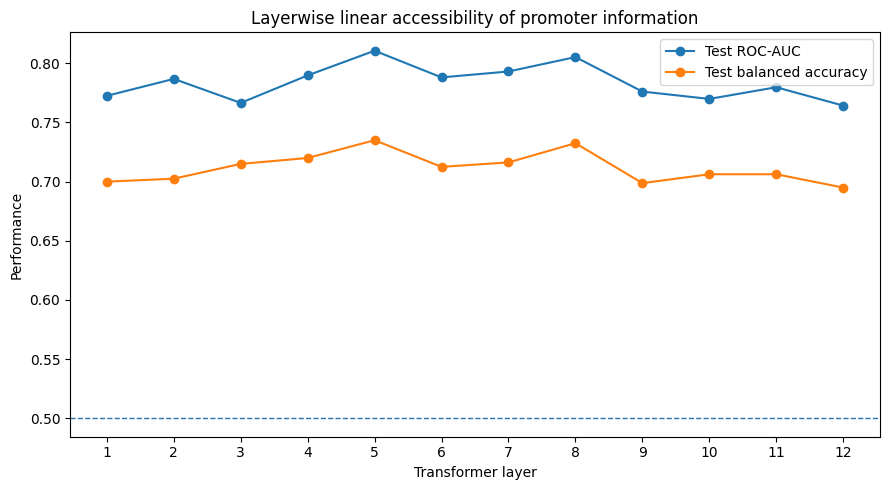

Results saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score

layerwise_rows = []
layerwise_probes = {}

for layer_index in range(N_LAYERS):
    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            random_state=SEED,
            solver="liblinear",
        ),
    )

    probe.fit(
        train_all_layers[:, layer_index, :],
        train_labels,
    )

    dev_probabilities = probe.predict_proba(
        dev_all_layers[:, layer_index, :]
    )[:, 1]

    test_probabilities = probe.predict_proba(
        test_all_layers[:, layer_index, :]
    )[:, 1]

    dev_predictions = (
        dev_probabilities >= 0.5
    ).astype(int)

    test_predictions = (
        test_probabilities >= 0.5
    ).astype(int)

    row = {
        "layer": layer_index + 1,
        "dev_balanced_accuracy": balanced_accuracy_score(
            dev_labels,
            dev_predictions,
        ),
        "dev_roc_auc": roc_auc_score(
            dev_labels,
            dev_probabilities,
        ),
        "test_balanced_accuracy": balanced_accuracy_score(
            test_labels,
            test_predictions,
        ),
        "test_roc_auc": roc_auc_score(
            test_labels,
            test_probabilities,
        ),
    }

    layerwise_rows.append(row)
    layerwise_probes[layer_index] = probe

layerwise_probe_results = pd.DataFrame(layerwise_rows)

display(
    layerwise_probe_results.sort_values(
        "test_roc_auc",
        ascending=False,
    )
)

best_layer_index = int(
    layerwise_probe_results.loc[
        layerwise_probe_results["test_roc_auc"].idxmax(),
        "layer",
    ]
) - 1

print(
    "\nBest test layer:",
    best_layer_index + 1,
)

print(
    "Best test ROC-AUC:",
    layerwise_probe_results.loc[
        layerwise_probe_results["layer"] == best_layer_index + 1,
        "test_roc_auc",
    ].iloc[0],
)

print(
    "Best test balanced accuracy:",
    layerwise_probe_results.loc[
        layerwise_probe_results["layer"] == best_layer_index + 1,
        "test_balanced_accuracy",
    ].iloc[0],
)

# Save every fitted probe.
for layer_index, probe in layerwise_probes.items():
    joblib.dump(
        probe,
        COMPONENT_DIR
        / f"layer_{layer_index + 1:02d}_probe.joblib",
    )

layerwise_probe_results.to_csv(
    COMPONENT_DIR / "layerwise_probe_results.csv",
    index=False,
)

# Plot layerwise performance.
plt.figure(figsize=(9, 5))

plt.plot(
    layerwise_probe_results["layer"],
    layerwise_probe_results["test_roc_auc"],
    marker="o",
    label="Test ROC-AUC",
)

plt.plot(
    layerwise_probe_results["layer"],
    layerwise_probe_results["test_balanced_accuracy"],
    marker="o",
    label="Test balanced accuracy",
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Transformer layer")
plt.ylabel("Performance")
plt.title("Layerwise linear accessibility of promoter information")
plt.xticks(range(1, N_LAYERS + 1))
plt.legend()
plt.tight_layout()

layerwise_figure_path = (
    COMPONENT_DIR / "layerwise_probe_performance.png"
)

plt.savefig(
    layerwise_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Results saved to:", COMPONENT_DIR)

# Cell 9 — Track promoter-evidence loss across layers

Recognized clean sequences: 291
Mononucleotide controls: 291
Dinucleotide controls: 291


Extracting all-layer representations:   0%|          | 0/10 [00:00<?, ?it/s]

Extracting all-layer representations:   0%|          | 0/10 [00:00<?, ?it/s]

Extracting all-layer representations:   0%|          | 0/10 [00:00<?, ?it/s]


Clean shape: (291, 12, 768)
Mono shape: (291, 12, 768)
Dinuc shape: (291, 12, 768)


,layer,mean_clean_logit,mean_mono_logit,mean_dinuc_logit,mean_mono_drop,median_mono_drop,fraction_mono_positive,mean_dinuc_drop,median_dinuc_drop,fraction_dinuc_positive
0,1,5.351480,0.233870,3.633539,5.117611,5.308864,0.742268,1.717941,2.164135,0.611684
1,2,6.528886,-0.329856,4.562321,6.858742,6.750807,0.752577,1.966565,1.756326,0.587629
2,3,6.531867,-0.133470,3.965451,6.665337,6.313269,0.728522,2.566416,3.248922,0.632302
3,4,5.816934,0.127746,3.257083,5.689188,5.542829,0.776632,2.559852,2.504736,0.646048
4,5,6.488243,0.118680,3.196015,6.369563,6.283646,0.852234,3.292228,2.961161,0.711340
5,6,5.631705,-0.369665,3.420596,6.001369,6.028221,0.786942,2.211108,2.276598,0.663230
6,7,5.016947,0.317873,2.853013,4.699074,4.590122,0.773196,2.163934,1.822555,0.632302
7,8,5.904619,0.108728,3.149570,5.795891,5.875796,0.807560,2.755048,2.648394,0.704467
8,9,5.643371,0.296809,3.711426,5.346562,5.226679,0.762887,1.931945,1.877166,0.621993
9,10,4.998304,-0.084392,3.181997,5.082696,5.013701,0.728522,1.816307,1.726287,0.611684


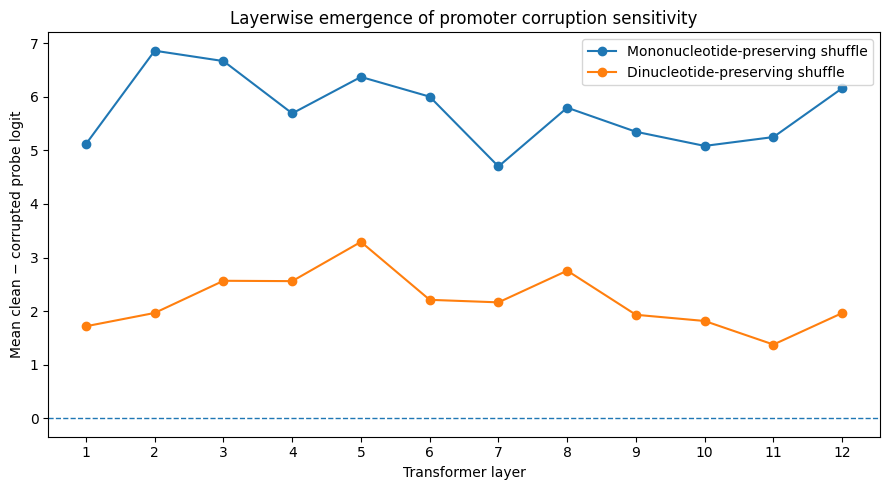

Saved layerwise corruption results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


In [ ]:
from ushuffle import shuffle as ushuffle_sequence
from ushuffle import set_seed as ushuffle_set_seed


def mononucleotide_shuffle(sequence, seed):
    rng = np.random.default_rng(seed)
    bases = np.array(list(sequence))
    rng.shuffle(bases)
    return "".join(bases.tolist())


def dinucleotide_shuffle(sequence, seed):
    ushuffle_set_seed(seed)

    shuffled = ushuffle_sequence(
        sequence.encode("ascii"),
        2,
    )

    return shuffled.decode("ascii")


recognized_sequences = (
    recognized_promoter_df["sequence"]
    .tolist()
)

recognized_clean_logits_layer5 = (
    recognized_promoter_df["clean_logit"]
    .to_numpy()
)

# Create one reproducible corruption of each type per promoter.
recognized_mono_sequences = []
recognized_dinuc_sequences = []

for sequence_index, sequence in enumerate(recognized_sequences):
    recognized_mono_sequences.append(
        mononucleotide_shuffle(
            sequence,
            seed=SEED + sequence_index,
        )
    )

    recognized_dinuc_sequences.append(
        dinucleotide_shuffle(
            sequence,
            seed=SEED + 100_000 + sequence_index,
        )
    )

print("Recognized clean sequences:", len(recognized_sequences))
print("Mononucleotide controls:", len(recognized_mono_sequences))
print("Dinucleotide controls:", len(recognized_dinuc_sequences))

# Extract all 12 layers.
recognized_clean_all_layers = extract_all_layer_representations(
    recognized_sequences,
    batch_size=32,
)

recognized_mono_all_layers = extract_all_layer_representations(
    recognized_mono_sequences,
    batch_size=32,
)

recognized_dinuc_all_layers = extract_all_layer_representations(
    recognized_dinuc_sequences,
    batch_size=32,
)

print("\nClean shape:", recognized_clean_all_layers.shape)
print("Mono shape:", recognized_mono_all_layers.shape)
print("Dinuc shape:", recognized_dinuc_all_layers.shape)

layerwise_corruption_rows = []
layerwise_sequence_rows = []

for layer_index in range(N_LAYERS):
    probe = layerwise_probes[layer_index]

    clean_logits = probe.decision_function(
        recognized_clean_all_layers[:, layer_index, :]
    )

    mono_logits = probe.decision_function(
        recognized_mono_all_layers[:, layer_index, :]
    )

    dinuc_logits = probe.decision_function(
        recognized_dinuc_all_layers[:, layer_index, :]
    )

    mono_drops = clean_logits - mono_logits
    dinuc_drops = clean_logits - dinuc_logits

    layerwise_corruption_rows.append({
        "layer": layer_index + 1,
        "mean_clean_logit": clean_logits.mean(),
        "mean_mono_logit": mono_logits.mean(),
        "mean_dinuc_logit": dinuc_logits.mean(),
        "mean_mono_drop": mono_drops.mean(),
        "median_mono_drop": np.median(mono_drops),
        "fraction_mono_positive": np.mean(mono_drops > 0),
        "mean_dinuc_drop": dinuc_drops.mean(),
        "median_dinuc_drop": np.median(dinuc_drops),
        "fraction_dinuc_positive": np.mean(dinuc_drops > 0),
    })

    for sequence_index in range(len(recognized_sequences)):
        layerwise_sequence_rows.append({
            "sequence_index": sequence_index,
            "layer": layer_index + 1,
            "clean_logit": clean_logits[sequence_index],
            "mono_logit": mono_logits[sequence_index],
            "dinuc_logit": dinuc_logits[sequence_index],
            "mono_drop": mono_drops[sequence_index],
            "dinuc_drop": dinuc_drops[sequence_index],
        })

layerwise_corruption_summary = pd.DataFrame(
    layerwise_corruption_rows
)

layerwise_corruption_long = pd.DataFrame(
    layerwise_sequence_rows
)

display(layerwise_corruption_summary)

# Plot layerwise corruption sensitivity.
plt.figure(figsize=(9, 5))

plt.plot(
    layerwise_corruption_summary["layer"],
    layerwise_corruption_summary["mean_mono_drop"],
    marker="o",
    label="Mononucleotide-preserving shuffle",
)

plt.plot(
    layerwise_corruption_summary["layer"],
    layerwise_corruption_summary["mean_dinuc_drop"],
    marker="o",
    label="Dinucleotide-preserving shuffle",
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Transformer layer")
plt.ylabel("Mean clean − corrupted probe logit")
plt.title(
    "Layerwise emergence of promoter corruption sensitivity"
)
plt.xticks(range(1, N_LAYERS + 1))
plt.legend()
plt.tight_layout()

corruption_layer_figure = (
    COMPONENT_DIR
    / "layerwise_clean_corrupt_logit_drop.png"
)

plt.savefig(
    corruption_layer_figure,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

layerwise_corruption_summary.to_csv(
    COMPONENT_DIR
    / "layerwise_clean_corrupt_summary.csv",
    index=False,
)

layerwise_corruption_long.to_csv(
    COMPONENT_DIR
    / "layerwise_clean_corrupt_per_sequence.csv",
    index=False,
)

np.save(
    COMPONENT_DIR
    / "recognized_clean_all_layers.npy",
    recognized_clean_all_layers,
)

np.save(
    COMPONENT_DIR
    / "recognized_mono_all_layers.npy",
    recognized_mono_all_layers,
)

np.save(
    COMPONENT_DIR
    / "recognized_dinuc_all_layers.npy",
    recognized_dinuc_all_layers,
)

print("Saved layerwise corruption results to:", COMPONENT_DIR)

# Cell 10 — Define branch ablations and verify intervention mechanics

In [ ]:
LAYER5_INDEX = 4


def zero_tensor_output_hook(module, inputs, output):
    """
    Replace a module's tensor output with zeros.

    Applied to:
    - attention.output.dense
    - mlp.wo

    This removes the branch update before the residual addition,
    rather than deleting the entire residual-stream state.
    """
    if isinstance(output, tuple):
        return tuple(
            torch.zeros_like(item)
            if torch.is_tensor(item)
            else item
            for item in output
        )

    if not torch.is_tensor(output):
        raise TypeError(
            f"Expected tensor output, received {type(output)}"
        )

    return torch.zeros_like(output)


def extract_layer5_with_optional_ablation(
    sequences,
    ablation_module=None,
    batch_size=32,
):
    """
    Extract mean-pooled Layer-5 representations, optionally while
    zeroing one internal branch module.
    """
    temporary_handle = None

    if ablation_module is not None:
        temporary_handle = ablation_module.register_forward_hook(
            zero_tensor_output_hook
        )

    try:
        dataloader = DataLoader(
            list(sequences),
            batch_size=batch_size,
            shuffle=False,
        )

        representation_batches = []

        for sequence_batch in tqdm(
            dataloader,
            desc="Scoring intervention",
        ):
            encoded = tokenizer(
                list(sequence_batch),
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=128,
            )

            encoded = {
                key: value.to(device)
                for key, value in encoded.items()
            }

            token_counts = (
                encoded["attention_mask"]
                .sum(dim=1)
                .tolist()
            )

            captured_layers.clear()

            with torch.no_grad():
                _ = backbone(
                    **encoded,
                    return_dict=False,
                )

            if LAYER5_INDEX not in captured_layers:
                raise RuntimeError(
                    "Layer-5 output was not captured."
                )

            pooled_layer5 = split_and_content_mean_pool(
                captured_layers[LAYER5_INDEX],
                token_counts,
            )

            representation_batches.append(
                pooled_layer5.cpu()
            )

        representations = (
            torch.cat(representation_batches, dim=0)
            .numpy()
        )

        logits = layer5_probe.decision_function(
            representations
        )

        probabilities = layer5_probe.predict_proba(
            representations
        )[:, 1]

        return representations, logits, probabilities

    finally:
        if temporary_handle is not None:
            temporary_handle.remove()


# Use a small cohort for the intervention smoke test.
intervention_smoke_sequences = recognized_sequences[:16]

# Clean reference.
(
    smoke_clean_representations,
    smoke_clean_logits,
    smoke_clean_probabilities,
) = extract_layer5_with_optional_ablation(
    intervention_smoke_sequences,
    ablation_module=None,
    batch_size=8,
)

# Layer-1 attention branch ablation.
layer1_attention_dense = (
    backbone.encoder.layer[0]
    .attention.output.dense
)

(
    smoke_attention_ablated_representations,
    smoke_attention_ablated_logits,
    smoke_attention_ablated_probabilities,
) = extract_layer5_with_optional_ablation(
    intervention_smoke_sequences,
    ablation_module=layer1_attention_dense,
    batch_size=8,
)

# Layer-1 MLP branch ablation.
layer1_mlp_output = (
    backbone.encoder.layer[0]
    .mlp.wo
)

(
    smoke_mlp_ablated_representations,
    smoke_mlp_ablated_logits,
    smoke_mlp_ablated_probabilities,
) = extract_layer5_with_optional_ablation(
    intervention_smoke_sequences,
    ablation_module=layer1_mlp_output,
    batch_size=8,
)

smoke_intervention_summary = pd.DataFrame([
    {
        "condition": "clean",
        "mean_logit": smoke_clean_logits.mean(),
        "mean_probability": smoke_clean_probabilities.mean(),
    },
    {
        "condition": "layer_1_attention_zero",
        "mean_logit": smoke_attention_ablated_logits.mean(),
        "mean_probability": (
            smoke_attention_ablated_probabilities.mean()
        ),
    },
    {
        "condition": "layer_1_mlp_zero",
        "mean_logit": smoke_mlp_ablated_logits.mean(),
        "mean_probability": (
            smoke_mlp_ablated_probabilities.mean()
        ),
    },
])

smoke_intervention_summary["mean_logit_drop"] = (
    smoke_clean_logits.mean()
    - smoke_intervention_summary["mean_logit"]
)

display(smoke_intervention_summary)

print(
    "Attention intervention changed representations:",
    not np.allclose(
        smoke_clean_representations,
        smoke_attention_ablated_representations,
    ),
)

print(
    "MLP intervention changed representations:",
    not np.allclose(
        smoke_clean_representations,
        smoke_mlp_ablated_representations,
    ),
)

assert not np.allclose(
    smoke_clean_representations,
    smoke_attention_ablated_representations,
)

assert not np.allclose(
    smoke_clean_representations,
    smoke_mlp_ablated_representations,
)

print("\nBranch-ablation smoke test passed.")

Scoring intervention:   0%|          | 0/2 [00:00<?, ?it/s]

Scoring intervention:   0%|          | 0/2 [00:00<?, ?it/s]

Scoring intervention:   0%|          | 0/2 [00:00<?, ?it/s]

,condition,mean_logit,mean_probability,mean_logit_drop
0,clean,7.544337,0.960021,0.000000
1,layer_1_attention_zero,-1.380355,0.315447,8.924692
2,layer_1_mlp_zero,-3.870517,0.308588,11.414854


Attention intervention changed representations: True
MLP intervention changed representations: True

Branch-ablation smoke test passed.


# Cell 11 — Branch-level necessity scan for the Layer-5 promoter signal

Scoring intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Ablating Layer 1 attention branch...


Scoring intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Ablating Layer 1 mlp branch...


Scoring intervention:   0%|          | 0/10 [00:00<?, ?it/s]

...


Ablating Layer 5 attention branch...


Scoring intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Ablating Layer 5 mlp branch...


Scoring intervention:   0%|          | 0/10 [00:00<?, ?it/s]

,layer,branch,mean_clean_logit,mean_ablated_logit,mean_logit_drop,median_logit_drop,std_logit_drop,fraction_positive_drop,mean_probability_drop,fraction_remaining_positive
1,1,mlp,6.488243,-5.703458,12.191701,10.268003,14.810739,0.835052,0.597925,0.333333
4,3,attention,6.488243,-4.622513,11.110756,11.811719,10.173065,0.900344,0.614384,0.319588
0,1,attention,6.488243,-2.922654,9.410898,9.912209,7.983634,0.914089,0.631305,0.305842
2,2,attention,6.488243,-1.971978,8.460221,8.156354,6.056173,0.920962,0.561128,0.364261
6,4,attention,6.488243,2.270513,4.217730,3.621219,6.057221,0.790378,0.305641,0.628866
9,5,mlp,6.488243,4.362516,2.125728,2.385397,8.772152,0.604811,0.298298,0.639175
3,2,mlp,6.488243,10.737359,-4.249116,-6.295441,15.075468,0.312715,0.119317,0.821306
5,3,mlp,6.488243,14.992007,-8.503764,-8.749844,9.164284,0.168385,-0.011029,0.948454
8,5,attention,6.488243,15.197150,-8.708907,-9.486811,7.034320,0.123711,-0.054743,0.996564
7,4,mlp,6.488243,26.673960,-20.185717,-20.077725,9.115707,0.013746,-0.062234,1.000000


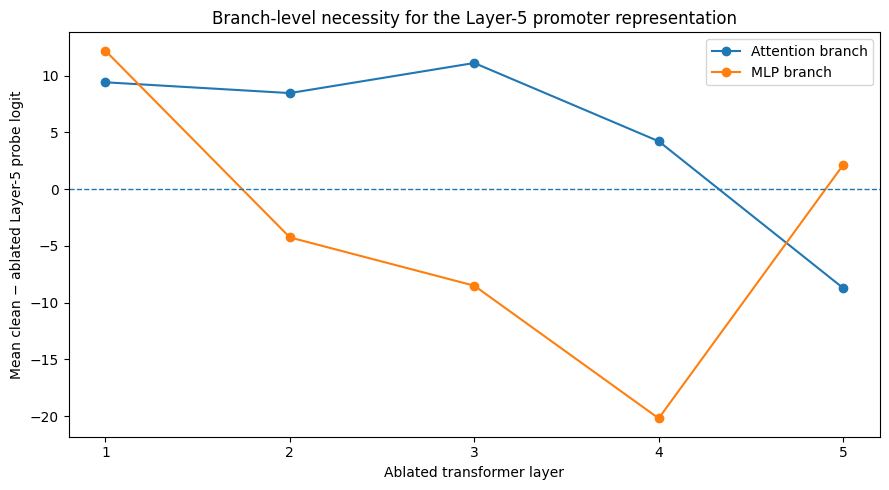


Branch scan saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


In [ ]:
INTERVENTION_LAYER_INDICES = list(range(LAYER5_INDEX + 1))
# Zero-based Layers 0–4, corresponding to Layers 1–5.

# Establish the clean reference on the full recognized cohort.
(
    branch_scan_clean_representations,
    branch_scan_clean_logits,
    branch_scan_clean_probabilities,
) = extract_layer5_with_optional_ablation(
    recognized_sequences,
    ablation_module=None,
    batch_size=32,
)

branch_scan_rows = []
branch_scan_per_sequence_rows = []

for layer_index in INTERVENTION_LAYER_INDICES:
    layer_number = layer_index + 1

    branch_modules = {
        "attention": (
            backbone.encoder.layer[layer_index]
            .attention.output.dense
        ),
        "mlp": (
            backbone.encoder.layer[layer_index]
            .mlp.wo
        ),
    }

    for branch_name, branch_module in branch_modules.items():
        print(
            f"\nAblating Layer {layer_number} "
            f"{branch_name} branch..."
        )

        (
            ablated_representations,
            ablated_logits,
            ablated_probabilities,
        ) = extract_layer5_with_optional_ablation(
            recognized_sequences,
            ablation_module=branch_module,
            batch_size=32,
        )

        logit_drops = (
            branch_scan_clean_logits
            - ablated_logits
        )

        probability_drops = (
            branch_scan_clean_probabilities
            - ablated_probabilities
        )

        branch_scan_rows.append({
            "layer": layer_number,
            "branch": branch_name,
            "mean_clean_logit": (
                branch_scan_clean_logits.mean()
            ),
            "mean_ablated_logit": (
                ablated_logits.mean()
            ),
            "mean_logit_drop": (
                logit_drops.mean()
            ),
            "median_logit_drop": (
                np.median(logit_drops)
            ),
            "std_logit_drop": (
                logit_drops.std(ddof=1)
            ),
            "fraction_positive_drop": (
                np.mean(logit_drops > 0)
            ),
            "mean_probability_drop": (
                probability_drops.mean()
            ),
            "fraction_remaining_positive": (
                np.mean(ablated_logits > 0)
            ),
        })

        for sequence_index in range(
            len(recognized_sequences)
        ):
            branch_scan_per_sequence_rows.append({
                "sequence_index": sequence_index,
                "layer": layer_number,
                "branch": branch_name,
                "clean_logit": (
                    branch_scan_clean_logits[
                        sequence_index
                    ]
                ),
                "ablated_logit": (
                    ablated_logits[
                        sequence_index
                    ]
                ),
                "logit_drop": (
                    logit_drops[
                        sequence_index
                    ]
                ),
                "clean_probability": (
                    branch_scan_clean_probabilities[
                        sequence_index
                    ]
                ),
                "ablated_probability": (
                    ablated_probabilities[
                        sequence_index
                    ]
                ),
                "probability_drop": (
                    probability_drops[
                        sequence_index
                    ]
                ),
            })


branch_scan_summary = pd.DataFrame(
    branch_scan_rows
)

branch_scan_per_sequence = pd.DataFrame(
    branch_scan_per_sequence_rows
)

display(
    branch_scan_summary.sort_values(
        "mean_logit_drop",
        ascending=False,
    )
)

# Plot attention and MLP effects separately.
branch_scan_pivot = (
    branch_scan_summary
    .pivot(
        index="layer",
        columns="branch",
        values="mean_logit_drop",
    )
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.plot(
    branch_scan_pivot["layer"],
    branch_scan_pivot["attention"],
    marker="o",
    label="Attention branch",
)

plt.plot(
    branch_scan_pivot["layer"],
    branch_scan_pivot["mlp"],
    marker="o",
    label="MLP branch",
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Ablated transformer layer")
plt.ylabel("Mean clean − ablated Layer-5 probe logit")
plt.title(
    "Branch-level necessity for the Layer-5 promoter representation"
)

plt.xticks(range(1, LAYER5_INDEX + 2))
plt.legend()
plt.tight_layout()

branch_scan_figure_path = (
    COMPONENT_DIR
    / "attention_mlp_branch_ablation_scan.png"
)

plt.savefig(
    branch_scan_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

branch_scan_summary.to_csv(
    COMPONENT_DIR
    / "attention_mlp_branch_ablation_summary.csv",
    index=False,
)

branch_scan_per_sequence.to_csv(
    COMPONENT_DIR
    / "attention_mlp_branch_ablation_per_sequence.csv",
    index=False,
)

print("\nBranch scan saved to:", COMPONENT_DIR)

# Cell 12 — Estimate mean branch for Layers 1–5 outputs for distribution-aware ablation

In [ ]:
REFERENCE_SEQUENCES = pilot_train["sequence"][:1000]

branch_mean_accumulators = {}
branch_mean_counts = {}
branch_mean_hooks = []

for layer_index in INTERVENTION_LAYER_INDICES:
    for branch_name, module in {
        "attention": (
            backbone.encoder.layer[layer_index]
            .attention.output.dense
        ),
        "mlp": (
            backbone.encoder.layer[layer_index]
            .mlp.wo
        ),
    }.items():
        key = (layer_index, branch_name)

        branch_mean_accumulators[key] = torch.zeros(
            backbone.config.hidden_size,
            dtype=torch.float64,
        )

        branch_mean_counts[key] = 0

        def make_mean_hook(cache_key):
            def hook(module, inputs, output):
                tensor = output[0] if isinstance(output, tuple) else output

                if not torch.is_tensor(tensor):
                    raise TypeError(
                        f"Expected tensor output, got {type(tensor)}"
                    )

                flat = tensor.detach().reshape(
                    -1,
                    tensor.shape[-1],
                )

                branch_mean_accumulators[cache_key] += (
                    flat.double()
                    .sum(dim=0)
                    .cpu()
                )

                branch_mean_counts[cache_key] += flat.shape[0]

            return hook

        branch_mean_hooks.append(
            module.register_forward_hook(
                make_mean_hook(key)
            )
        )


reference_loader = DataLoader(
    list(REFERENCE_SEQUENCES),
    batch_size=32,
    shuffle=False,
)

for sequence_batch in tqdm(
    reference_loader,
    desc="Estimating branch means",
):
    encoded = tokenizer(
        list(sequence_batch),
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128,
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    with torch.no_grad():
        _ = backbone(
            **encoded,
            return_dict=False,
        )


for handle in branch_mean_hooks:
    handle.remove()


branch_means = {}

for key in branch_mean_accumulators:
    branch_means[key] = (
        branch_mean_accumulators[key]
        / branch_mean_counts[key]
    ).float()

branch_mean_summary = pd.DataFrame([
    {
        "layer": layer_index + 1,
        "branch": branch_name,
        "token_count": branch_mean_counts[
            (layer_index, branch_name)
        ],
        "mean_vector_norm": torch.linalg.vector_norm(
            branch_means[(layer_index, branch_name)]
        ).item(),
    }
    for layer_index in INTERVENTION_LAYER_INDICES
    for branch_name in ["attention", "mlp"]
])

display(branch_mean_summary)

torch.save(
    branch_means,
    COMPONENT_DIR / "branch_reference_means.pt",
)

print(
    "\nSaved branch means to:",
    COMPONENT_DIR / "branch_reference_means.pt",
)

Estimating branch means:   0%|          | 0/32 [00:00<?, ?it/s]

,layer,branch,token_count,mean_vector_norm
0,1,attention,17428,1.968113
1,1,mlp,17428,6.806325
2,2,attention,17428,3.315075
3,2,mlp,17428,3.216201
4,3,attention,17428,4.374729
5,3,mlp,17428,5.452249
6,4,attention,17428,5.403912
7,4,mlp,17428,79.655373
8,5,attention,17428,6.252531
9,5,mlp,17428,53.613365



Saved branch means to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization/branch_reference_means.pt


# Cell 13 — Distribution-aware branch ablation by mean replacement


Mean-replacing Layer 1 attention branch...


Mean-replacement intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Mean-replacing Layer 1 mlp branch...


Mean-replacement intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Mean-replacing Layer 2 attention branch...


...

Mean-replacement intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Mean-replacing Layer 5 mlp branch...


Mean-replacement intervention:   0%|          | 0/10 [00:00<?, ?it/s]

,layer,branch,mean_clean_logit,mean_replaced_logit,mean_logit_drop,median_logit_drop,std_logit_drop,fraction_positive_drop,mean_probability_drop,fraction_remaining_positive
0,1,attention,6.488243,-1.242400,7.730643,7.319912,6.638149,0.910653,0.552976,0.374570
1,1,mlp,6.488243,-1.073129,7.561372,6.905104,7.543862,0.886598,0.534359,0.371134
2,2,attention,6.488243,1.305461,5.182783,5.259867,5.252126,0.831615,0.387570,0.549828
6,4,attention,6.488243,3.124483,3.363761,3.037795,4.532827,0.800687,0.171525,0.780069
7,4,mlp,6.488243,4.136741,2.351502,1.295547,5.218363,0.621993,-0.045883,1.000000
8,5,attention,6.488243,4.193112,2.295132,1.333619,6.555587,0.594502,0.154725,0.783505
4,3,attention,6.488243,4.484060,2.004183,2.637246,9.275523,0.597938,0.309485,0.625430
9,5,mlp,6.488243,5.122873,1.365370,0.525183,4.566978,0.539519,-0.033391,0.996564
3,2,mlp,6.488243,5.263048,1.225196,0.208610,12.769496,0.505155,0.258476,0.676976
5,3,mlp,6.488243,7.648566,-1.160323,-1.956252,5.131813,0.360825,-0.058229,1.000000


,layer,branch,zero_ablation_drop,zero_fraction_positive,mean_replacement_drop,mean_replacement_fraction_positive,sign_agreement
0,1,attention,9.410898,0.914089,7.730643,0.910653,True
1,1,mlp,12.191701,0.835052,7.561372,0.886598,True
2,2,attention,8.460221,0.920962,5.182783,0.831615,True
6,4,attention,4.217730,0.790378,3.363761,0.800687,True
7,4,mlp,-20.185717,0.013746,2.351502,0.621993,False
8,5,attention,-8.708907,0.123711,2.295132,0.594502,False
4,3,attention,11.110756,0.900344,2.004183,0.597938,True
9,5,mlp,2.125728,0.604811,1.365370,0.539519,True
3,2,mlp,-4.249116,0.312715,1.225196,0.505155,False
5,3,mlp,-8.503764,0.168385,-1.160323,0.360825,True


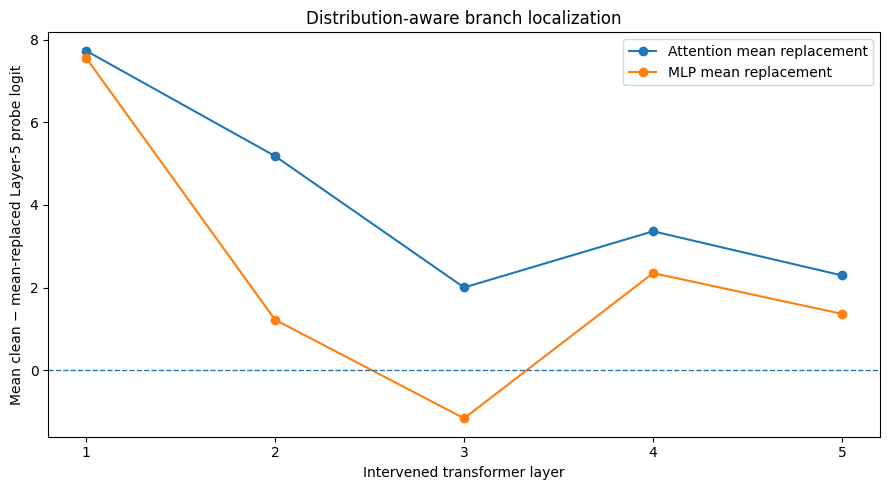


Mean-replacement scan saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


In [ ]:
def make_mean_replacement_hook(mean_vector):
    """
    Replace every token's branch output with the reference mean vector.

    This removes sequence-specific branch information while preserving
    a more natural activation scale than zero ablation.
    """
    def hook(module, inputs, output):
        tensor = output[0] if isinstance(output, tuple) else output

        if not torch.is_tensor(tensor):
            raise TypeError(
                f"Expected tensor output, got {type(tensor)}"
            )

        replacement = mean_vector.to(
            device=tensor.device,
            dtype=tensor.dtype,
        )

        while replacement.ndim < tensor.ndim:
            replacement = replacement.unsqueeze(0)

        replacement = replacement.expand_as(tensor)

        if isinstance(output, tuple):
            output_items = list(output)
            output_items[0] = replacement
            return tuple(output_items)

        return replacement

    return hook


def extract_layer5_with_mean_replacement(
    sequences,
    replacement_module,
    replacement_mean,
    batch_size=32,
):
    handle = replacement_module.register_forward_hook(
        make_mean_replacement_hook(replacement_mean)
    )

    try:
        dataloader = DataLoader(
            list(sequences),
            batch_size=batch_size,
            shuffle=False,
        )

        representation_batches = []

        for sequence_batch in tqdm(
            dataloader,
            desc="Mean-replacement intervention",
        ):
            encoded = tokenizer(
                list(sequence_batch),
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=128,
            )

            encoded = {
                key: value.to(device)
                for key, value in encoded.items()
            }

            token_counts = (
                encoded["attention_mask"]
                .sum(dim=1)
                .tolist()
            )

            captured_layers.clear()

            with torch.no_grad():
                _ = backbone(
                    **encoded,
                    return_dict=False,
                )

            pooled_layer5 = split_and_content_mean_pool(
                captured_layers[LAYER5_INDEX],
                token_counts,
            )

            representation_batches.append(
                pooled_layer5.cpu()
            )

        representations = (
            torch.cat(representation_batches, dim=0)
            .numpy()
        )

        logits = layer5_probe.decision_function(
            representations
        )

        probabilities = layer5_probe.predict_proba(
            representations
        )[:, 1]

        return representations, logits, probabilities

    finally:
        handle.remove()


mean_replacement_rows = []
mean_replacement_per_sequence_rows = []

for layer_index in INTERVENTION_LAYER_INDICES:
    layer_number = layer_index + 1

    branch_modules = {
        "attention": (
            backbone.encoder.layer[layer_index]
            .attention.output.dense
        ),
        "mlp": (
            backbone.encoder.layer[layer_index]
            .mlp.wo
        ),
    }

    for branch_name, branch_module in branch_modules.items():
        print(
            f"\nMean-replacing Layer {layer_number} "
            f"{branch_name} branch..."
        )

        reference_mean = branch_means[
            (layer_index, branch_name)
        ]

        (
            mean_replaced_representations,
            mean_replaced_logits,
            mean_replaced_probabilities,
        ) = extract_layer5_with_mean_replacement(
            recognized_sequences,
            replacement_module=branch_module,
            replacement_mean=reference_mean,
            batch_size=32,
        )

        logit_drops = (
            branch_scan_clean_logits
            - mean_replaced_logits
        )

        probability_drops = (
            branch_scan_clean_probabilities
            - mean_replaced_probabilities
        )

        mean_replacement_rows.append({
            "layer": layer_number,
            "branch": branch_name,
            "mean_clean_logit": (
                branch_scan_clean_logits.mean()
            ),
            "mean_replaced_logit": (
                mean_replaced_logits.mean()
            ),
            "mean_logit_drop": logit_drops.mean(),
            "median_logit_drop": np.median(logit_drops),
            "std_logit_drop": logit_drops.std(ddof=1),
            "fraction_positive_drop": (
                np.mean(logit_drops > 0)
            ),
            "mean_probability_drop": (
                probability_drops.mean()
            ),
            "fraction_remaining_positive": (
                np.mean(mean_replaced_logits > 0)
            ),
        })

        for sequence_index in range(
            len(recognized_sequences)
        ):
            mean_replacement_per_sequence_rows.append({
                "sequence_index": sequence_index,
                "layer": layer_number,
                "branch": branch_name,
                "clean_logit": (
                    branch_scan_clean_logits[
                        sequence_index
                    ]
                ),
                "mean_replaced_logit": (
                    mean_replaced_logits[
                        sequence_index
                    ]
                ),
                "logit_drop": (
                    logit_drops[
                        sequence_index
                    ]
                ),
                "probability_drop": (
                    probability_drops[
                        sequence_index
                    ]
                ),
            })


mean_replacement_summary = pd.DataFrame(
    mean_replacement_rows
)

mean_replacement_per_sequence = pd.DataFrame(
    mean_replacement_per_sequence_rows
)

display(
    mean_replacement_summary.sort_values(
        "mean_logit_drop",
        ascending=False,
    )
)

# Compare zero versus mean replacement.
branch_intervention_comparison = (
    branch_scan_summary[
        [
            "layer",
            "branch",
            "mean_logit_drop",
            "fraction_positive_drop",
        ]
    ]
    .rename(columns={
        "mean_logit_drop": "zero_ablation_drop",
        "fraction_positive_drop": (
            "zero_fraction_positive"
        ),
    })
    .merge(
        mean_replacement_summary[
            [
                "layer",
                "branch",
                "mean_logit_drop",
                "fraction_positive_drop",
            ]
        ].rename(columns={
            "mean_logit_drop": (
                "mean_replacement_drop"
            ),
            "fraction_positive_drop": (
                "mean_replacement_fraction_positive"
            ),
        }),
        on=["layer", "branch"],
    )
)

branch_intervention_comparison[
    "sign_agreement"
] = (
    np.sign(
        branch_intervention_comparison[
            "zero_ablation_drop"
        ]
    )
    ==
    np.sign(
        branch_intervention_comparison[
            "mean_replacement_drop"
        ]
    )
)

display(
    branch_intervention_comparison.sort_values(
        "mean_replacement_drop",
        ascending=False,
    )
)

# Plot distribution-aware effects.
mean_replacement_pivot = (
    mean_replacement_summary
    .pivot(
        index="layer",
        columns="branch",
        values="mean_logit_drop",
    )
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.plot(
    mean_replacement_pivot["layer"],
    mean_replacement_pivot["attention"],
    marker="o",
    label="Attention mean replacement",
)

plt.plot(
    mean_replacement_pivot["layer"],
    mean_replacement_pivot["mlp"],
    marker="o",
    label="MLP mean replacement",
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Intervened transformer layer")
plt.ylabel("Mean clean − mean-replaced Layer-5 probe logit")
plt.title(
    "Distribution-aware branch localization"
)

plt.xticks(range(1, LAYER5_INDEX + 2))
plt.legend()
plt.tight_layout()

mean_replacement_figure_path = (
    COMPONENT_DIR
    / "attention_mlp_mean_replacement_scan.png"
)

plt.savefig(
    mean_replacement_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

mean_replacement_summary.to_csv(
    COMPONENT_DIR
    / "attention_mlp_mean_replacement_summary.csv",
    index=False,
)

mean_replacement_per_sequence.to_csv(
    COMPONENT_DIR
    / "attention_mlp_mean_replacement_per_sequence.csv",
    index=False,
)

branch_intervention_comparison.to_csv(
    COMPONENT_DIR
    / "zero_vs_mean_replacement_comparison.csv",
    index=False,
)

print("\nMean-replacement scan saved to:", COMPONENT_DIR)

# Cell 14 — Inspect DNABERT-2 attention tensor layout before head interventions

In [ ]:
import inspect

attention_class = type(
    backbone.encoder.layer[0].attention.self
)

print("Attention class:", attention_class)
print("\nForward signature:")
print(
    inspect.signature(
        backbone.encoder.layer[0].attention.self.forward
    )
)

print("\nSelf-attention forward source:")
print(
    inspect.getsource(
        backbone.encoder.layer[0].attention.self.forward
    )
)

print("\nAttention wrapper forward source:")
print(
    inspect.getsource(
        backbone.encoder.layer[0].attention.forward
    )
)

Attention class: <class 'transformers_modules.quietflamingo.dnabert2-no-flashattention.813031b2bf86d9e960a027e2734c908009f31601.bert_layers.BertUnpadSelfAttention'>

Forward signature:
(hidden_states: torch.Tensor, cu_seqlens: torch.Tensor, max_seqlen_in_batch: int, indices: torch.Tensor, attn_mask: torch.Tensor, bias: torch.Tensor) -> torch.Tensor

Self-attention forward source:
    def forward(self, hidden_states: torch.Tensor, cu_seqlens: torch.Tensor,
                max_seqlen_in_batch: int, indices: torch.Tensor,
                attn_mask: torch.Tensor, bias: torch.Tensor) -> torch.Tensor:
        """Perform self-attention.

        If dropout is zero, then we can use the Triton kernel, so we do that. However, if not, we send through a standard PyTorch
        implementation of self-attention.

        The arguments are unpadded, and our implementations of attention require padded arguments,
        so we first call `pad_input`. Once we compute attention, we re-unpad our outputs 

# Cell 15 — Cache mean output vectors for individual attention heads

In [ ]:
CANDIDATE_ATTENTION_LAYERS = [0, 1, 3]
# Zero-based indices corresponding to Layers 1, 2, and 4.

NUM_HEADS = backbone.config.num_attention_heads
HEAD_DIM = backbone.config.hidden_size // NUM_HEADS

print("Candidate attention layers:",
      [index + 1 for index in CANDIDATE_ATTENTION_LAYERS])
print("Number of heads:", NUM_HEADS)
print("Head dimension:", HEAD_DIM)

head_sum_accumulators = {}
head_token_counts = {}
head_mean_hooks = []

for layer_index in CANDIDATE_ATTENTION_LAYERS:
    head_sum_accumulators[layer_index] = torch.zeros(
        NUM_HEADS,
        HEAD_DIM,
        dtype=torch.float64,
    )

    head_token_counts[layer_index] = 0

    def make_head_mean_hook(cache_layer_index):
        def hook(module, inputs, output):
            if not torch.is_tensor(output):
                raise TypeError(
                    f"Expected tensor output, received {type(output)}"
                )

            if output.ndim != 2:
                raise ValueError(
                    f"Expected [tokens, hidden], received {output.shape}"
                )

            head_output = output.detach().reshape(
                output.shape[0],
                NUM_HEADS,
                HEAD_DIM,
            )

            head_sum_accumulators[cache_layer_index] += (
                head_output
                .double()
                .sum(dim=0)
                .cpu()
            )

            head_token_counts[cache_layer_index] += (
                head_output.shape[0]
            )

        return hook

    attention_self_module = (
        backbone.encoder.layer[layer_index]
        .attention.self
    )

    head_mean_hooks.append(
        attention_self_module.register_forward_hook(
            make_head_mean_hook(layer_index)
        )
    )


# Reuse the 1,000 training sequences selected for branch means.
head_reference_loader = DataLoader(
    list(REFERENCE_SEQUENCES),
    batch_size=32,
    shuffle=False,
)

for sequence_batch in tqdm(
    head_reference_loader,
    desc="Estimating per-head means",
):
    encoded = tokenizer(
        list(sequence_batch),
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=128,
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    with torch.no_grad():
        _ = backbone(
            **encoded,
            return_dict=False,
        )


for handle in head_mean_hooks:
    handle.remove()


head_reference_means = {}

for layer_index in CANDIDATE_ATTENTION_LAYERS:
    head_reference_means[layer_index] = (
        head_sum_accumulators[layer_index]
        / head_token_counts[layer_index]
    ).float()


head_mean_summary_rows = []

for layer_index in CANDIDATE_ATTENTION_LAYERS:
    for head_index in range(NUM_HEADS):
        mean_vector = (
            head_reference_means[layer_index][head_index]
        )

        head_mean_summary_rows.append({
            "layer": layer_index + 1,
            "head": head_index + 1,
            "token_count": head_token_counts[layer_index],
            "mean_vector_norm": torch.linalg.vector_norm(
                mean_vector
            ).item(),
        })


head_mean_summary = pd.DataFrame(
    head_mean_summary_rows
)

display(head_mean_summary)

torch.save(
    head_reference_means,
    COMPONENT_DIR / "attention_head_reference_means.pt",
)

head_mean_summary.to_csv(
    COMPONENT_DIR / "attention_head_reference_mean_summary.csv",
    index=False,
)

print(
    "\nSaved per-head means to:",
    COMPONENT_DIR / "attention_head_reference_means.pt",
)

Candidate attention layers: [1, 2, 4]
Number of heads: 12
Head dimension: 64


Estimating per-head means:   0%|          | 0/32 [00:00<?, ?it/s]

,layer,head,token_count,mean_vector_norm
0,1,1,17428,0.334785
1,1,2,17428,1.249885
2,1,3,17428,0.340155
3,1,4,17428,0.943148
4,1,5,17428,0.087315
5,1,6,17428,0.617201
6,1,7,17428,0.830538
7,1,8,17428,0.651164
8,1,9,17428,0.824084
9,1,10,17428,0.160862



Saved per-head means to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization/attention_head_reference_means.pt


# Cell 16 — Verify that one-head replacement works correctly

In [ ]:
def make_single_head_replacement_hook(
    head_index,
    head_mean_vector,
):
    """
    Replace one attention head's output with its reference mean.

    Input/output shape at attention.self:
        [total_nonpadding_tokens, hidden_size]

    Reshaped:
        [total_nonpadding_tokens, num_heads, head_dim]
    """
    def hook(module, inputs, output):
        if not torch.is_tensor(output):
            raise TypeError(
                f"Expected tensor output, received {type(output)}"
            )

        if output.ndim != 2:
            raise ValueError(
                f"Expected [tokens, hidden], received {output.shape}"
            )

        reshaped = output.reshape(
            output.shape[0],
            NUM_HEADS,
            HEAD_DIM,
        ).clone()

        replacement = head_mean_vector.to(
            device=output.device,
            dtype=output.dtype,
        )

        reshaped[:, head_index, :] = replacement

        return reshaped.reshape(
            output.shape[0],
            backbone.config.hidden_size,
        )

    return hook


def extract_layer5_with_head_replacement(
    sequences,
    layer_index,
    head_index,
    head_mean_vector,
    batch_size=32,
):
    attention_self_module = (
        backbone.encoder.layer[layer_index]
        .attention.self
    )

    handle = attention_self_module.register_forward_hook(
        make_single_head_replacement_hook(
            head_index=head_index,
            head_mean_vector=head_mean_vector,
        )
    )

    try:
        dataloader = DataLoader(
            list(sequences),
            batch_size=batch_size,
            shuffle=False,
        )

        representation_batches = []

        for sequence_batch in tqdm(
            dataloader,
            desc=(
                f"Replacing L{layer_index + 1}"
                f"H{head_index + 1}"
            ),
        ):
            encoded = tokenizer(
                list(sequence_batch),
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=128,
            )

            encoded = {
                key: value.to(device)
                for key, value in encoded.items()
            }

            token_counts = (
                encoded["attention_mask"]
                .sum(dim=1)
                .tolist()
            )

            captured_layers.clear()

            with torch.no_grad():
                _ = backbone(
                    **encoded,
                    return_dict=False,
                )

            pooled_layer5 = split_and_content_mean_pool(
                captured_layers[LAYER5_INDEX],
                token_counts,
            )

            representation_batches.append(
                pooled_layer5.cpu()
            )

        representations = (
            torch.cat(representation_batches, dim=0)
            .numpy()
        )

        logits = layer5_probe.decision_function(
            representations
        )

        probabilities = layer5_probe.predict_proba(
            representations
        )[:, 1]

        return representations, logits, probabilities

    finally:
        handle.remove()


# Smoke-test Layer 1, Head 1.
SMOKE_LAYER_INDEX = 0
SMOKE_HEAD_INDEX = 0

head_smoke_sequences = recognized_sequences[:16]

(
    head_smoke_clean_representations,
    head_smoke_clean_logits,
    head_smoke_clean_probabilities,
) = extract_layer5_with_optional_ablation(
    head_smoke_sequences,
    ablation_module=None,
    batch_size=8,
)

(
    head_smoke_replaced_representations,
    head_smoke_replaced_logits,
    head_smoke_replaced_probabilities,
) = extract_layer5_with_head_replacement(
    head_smoke_sequences,
    layer_index=SMOKE_LAYER_INDEX,
    head_index=SMOKE_HEAD_INDEX,
    head_mean_vector=(
        head_reference_means[SMOKE_LAYER_INDEX][
            SMOKE_HEAD_INDEX
        ]
    ),
    batch_size=8,
)

head_smoke_summary = pd.DataFrame([
    {
        "condition": "clean",
        "mean_logit": head_smoke_clean_logits.mean(),
        "mean_probability": (
            head_smoke_clean_probabilities.mean()
        ),
    },
    {
        "condition": "L1H1 mean replacement",
        "mean_logit": head_smoke_replaced_logits.mean(),
        "mean_probability": (
            head_smoke_replaced_probabilities.mean()
        ),
    },
])

head_smoke_summary["mean_logit_drop"] = (
    head_smoke_clean_logits.mean()
    - head_smoke_summary["mean_logit"]
)

display(head_smoke_summary)

print(
    "Head intervention changed Layer-5 representations:",
    not np.allclose(
        head_smoke_clean_representations,
        head_smoke_replaced_representations,
    ),
)

assert not np.allclose(
    head_smoke_clean_representations,
    head_smoke_replaced_representations,
)

print("\nSingle-head replacement smoke test passed.")

Scoring intervention:   0%|          | 0/2 [00:00<?, ?it/s]

Replacing L1H1:   0%|          | 0/2 [00:00<?, ?it/s]

,condition,mean_logit,mean_probability,mean_logit_drop
0,clean,7.544337,0.960021,0.000000
1,L1H1 mean replacement,7.254287,0.954405,0.290051


Head intervention changed Layer-5 representations: True

Single-head replacement smoke test passed.


# Cell 17 — Mean-replacement scan across all 36 candidate attention heads


Scanning Layer 1, Head 1...


Replacing L1H1:   0%|          | 0/10 [00:00<?, ?it/s]


Scanning Layer 1, Head 2...


Replacing L1H2:   0%|          | 0/10 [00:00<?, ?it/s]


Scanning Layer 1, Head 3...


...


Scanning Layer 4, Head 11...


Replacing L4H11:   0%|          | 0/10 [00:00<?, ?it/s]


Scanning Layer 4, Head 12...


Replacing L4H12:   0%|          | 0/10 [00:00<?, ?it/s]

,layer,head,mean_clean_logit,mean_replaced_logit,mean_logit_drop,median_logit_drop,std_logit_drop,fraction_positive_drop,mean_probability_drop,fraction_remaining_positive
8,1,9,6.488243,-0.157686,6.645930,6.717012,5.949915,0.879725,0.461069,0.484536
1,1,2,6.488243,0.589018,5.899225,4.635349,8.305516,0.797251,0.399269,0.539519
10,1,11,6.488243,4.136398,2.351846,2.863939,4.772605,0.704467,0.231733,0.704467
20,2,9,6.488243,4.416249,2.071995,1.916218,3.054921,0.780069,0.181043,0.762887
12,2,1,6.488243,4.570166,1.918078,1.878127,2.710968,0.786942,0.168002,0.766323
22,2,11,6.488243,5.458222,1.030021,0.848433,1.612402,0.749141,0.047712,0.920962
2,1,3,6.488243,5.465714,1.022529,0.820142,5.229577,0.694158,0.088154,0.876289
25,4,2,6.488243,5.712318,0.775925,0.645268,1.273240,0.749141,0.045653,0.924399
7,1,8,6.488243,5.767849,0.720395,-0.130547,5.350623,0.470790,0.053236,0.914089
11,1,12,6.488243,5.810228,0.678015,0.415507,3.830102,0.628866,0.035706,0.945017


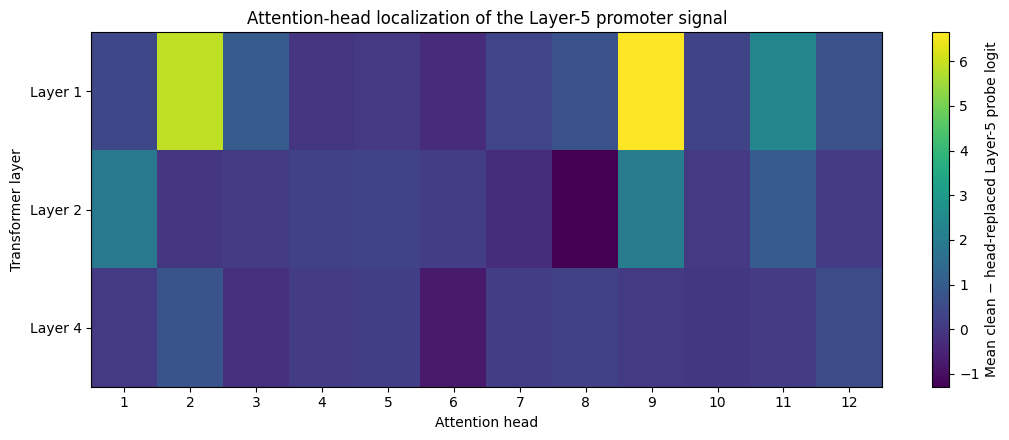


Head scan saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


In [ ]:
head_scan_rows = []
head_scan_per_sequence_rows = []

# Clean reference for the full recognized cohort.
clean_head_scan_logits = branch_scan_clean_logits
clean_head_scan_probabilities = branch_scan_clean_probabilities

for layer_index in CANDIDATE_ATTENTION_LAYERS:
    for head_index in range(NUM_HEADS):
        print(
            f"\nScanning Layer {layer_index + 1}, "
            f"Head {head_index + 1}..."
        )

        (
            replaced_representations,
            replaced_logits,
            replaced_probabilities,
        ) = extract_layer5_with_head_replacement(
            recognized_sequences,
            layer_index=layer_index,
            head_index=head_index,
            head_mean_vector=(
                head_reference_means[layer_index][head_index]
            ),
            batch_size=32,
        )

        logit_drops = (
            clean_head_scan_logits
            - replaced_logits
        )

        probability_drops = (
            clean_head_scan_probabilities
            - replaced_probabilities
        )

        head_scan_rows.append({
            "layer": layer_index + 1,
            "head": head_index + 1,
            "mean_clean_logit": (
                clean_head_scan_logits.mean()
            ),
            "mean_replaced_logit": (
                replaced_logits.mean()
            ),
            "mean_logit_drop": (
                logit_drops.mean()
            ),
            "median_logit_drop": (
                np.median(logit_drops)
            ),
            "std_logit_drop": (
                logit_drops.std(ddof=1)
            ),
            "fraction_positive_drop": (
                np.mean(logit_drops > 0)
            ),
            "mean_probability_drop": (
                probability_drops.mean()
            ),
            "fraction_remaining_positive": (
                np.mean(replaced_logits > 0)
            ),
        })

        for sequence_index in range(
            len(recognized_sequences)
        ):
            head_scan_per_sequence_rows.append({
                "sequence_index": sequence_index,
                "layer": layer_index + 1,
                "head": head_index + 1,
                "clean_logit": (
                    clean_head_scan_logits[
                        sequence_index
                    ]
                ),
                "replaced_logit": (
                    replaced_logits[
                        sequence_index
                    ]
                ),
                "logit_drop": (
                    logit_drops[
                        sequence_index
                    ]
                ),
                "clean_probability": (
                    clean_head_scan_probabilities[
                        sequence_index
                    ]
                ),
                "replaced_probability": (
                    replaced_probabilities[
                        sequence_index
                    ]
                ),
                "probability_drop": (
                    probability_drops[
                        sequence_index
                    ]
                ),
            })


head_scan_summary = pd.DataFrame(
    head_scan_rows
)

head_scan_per_sequence = pd.DataFrame(
    head_scan_per_sequence_rows
)

display(
    head_scan_summary.sort_values(
        [
            "mean_logit_drop",
            "fraction_positive_drop",
        ],
        ascending=False,
    )
)

# Heatmap-style matrix using imshow.
head_effect_matrix = np.full(
    (len(CANDIDATE_ATTENTION_LAYERS), NUM_HEADS),
    np.nan,
)

for row_index, layer_index in enumerate(
    CANDIDATE_ATTENTION_LAYERS
):
    layer_rows = (
        head_scan_summary[
            head_scan_summary["layer"] == layer_index + 1
        ]
        .sort_values("head")
    )

    head_effect_matrix[row_index, :] = (
        layer_rows["mean_logit_drop"].to_numpy()
    )

plt.figure(figsize=(11, 4.5))

image = plt.imshow(
    head_effect_matrix,
    aspect="auto",
)

plt.colorbar(
    image,
    label="Mean clean − head-replaced Layer-5 probe logit",
)

plt.xticks(
    ticks=np.arange(NUM_HEADS),
    labels=np.arange(1, NUM_HEADS + 1),
)

plt.yticks(
    ticks=np.arange(
        len(CANDIDATE_ATTENTION_LAYERS)
    ),
    labels=[
        f"Layer {layer_index + 1}"
        for layer_index in CANDIDATE_ATTENTION_LAYERS
    ],
)

plt.xlabel("Attention head")
plt.ylabel("Transformer layer")
plt.title(
    "Attention-head localization of the Layer-5 promoter signal"
)

plt.tight_layout()

head_scan_figure_path = (
    COMPONENT_DIR
    / "candidate_attention_head_scan.png"
)

plt.savefig(
    head_scan_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

head_scan_summary.to_csv(
    COMPONENT_DIR
    / "candidate_attention_head_scan_summary.csv",
    index=False,
)

head_scan_per_sequence.to_csv(
    COMPONENT_DIR
    / "candidate_attention_head_scan_per_sequence.csv",
    index=False,
)

print("\nHead scan saved to:", COMPONENT_DIR)

# Cell 18 — Bootstrap uncertainty and robust ranking of candidate heads

,layer,head,component,mean_logit_drop,median_logit_drop,ci_2.5,ci_97.5,standard_error,fraction_positive,robust_candidate
0,1,9,L1H9,6.645930,6.717012,5.970332,7.316443,0.344539,0.879725,True
1,1,2,L1H2,5.899225,4.635349,4.961343,6.891519,0.491658,0.797251,True
2,1,11,L1H11,2.351846,2.863939,1.809797,2.909898,0.278390,0.704467,True
3,2,9,L2H9,2.071995,1.916218,1.721578,2.429242,0.181414,0.780069,True
4,2,1,L2H1,1.918078,1.878127,1.610254,2.221920,0.157354,0.786942,True
5,2,11,L2H11,1.030021,0.848433,0.846423,1.220912,0.095733,0.749141,True
6,1,3,L1H3,1.022529,0.820142,0.397836,1.616333,0.307832,0.694158,True
7,4,2,L4H2,0.775925,0.645268,0.632407,0.925950,0.074807,0.749141,True
8,1,8,L1H8,0.720395,-0.130547,0.139002,1.375635,0.314250,0.470790,False
9,1,12,L1H12,0.678015,0.415507,0.237061,1.096083,0.218148,0.628866,True



Robust candidate heads:


,layer,head,component,mean_logit_drop,median_logit_drop,ci_2.5,ci_97.5,standard_error,fraction_positive,robust_candidate
0,1,9,L1H9,6.645930,6.717012,5.970332,7.316443,0.344539,0.879725,True
1,1,2,L1H2,5.899225,4.635349,4.961343,6.891519,0.491658,0.797251,True
2,1,11,L1H11,2.351846,2.863939,1.809797,2.909898,0.278390,0.704467,True
3,2,9,L2H9,2.071995,1.916218,1.721578,2.429242,0.181414,0.780069,True
4,2,1,L2H1,1.918078,1.878127,1.610254,2.221920,0.157354,0.786942,True
5,2,11,L2H11,1.030021,0.848433,0.846423,1.220912,0.095733,0.749141,True
6,1,3,L1H3,1.022529,0.820142,0.397836,1.616333,0.307832,0.694158,True
7,4,2,L4H2,0.775925,0.645268,0.632407,0.925950,0.074807,0.749141,True
9,1,12,L1H12,0.678015,0.415507,0.237061,1.096083,0.218148,0.628866,True
10,4,12,L4H12,0.569848,0.488947,0.384953,0.755518,0.095134,0.632302,True


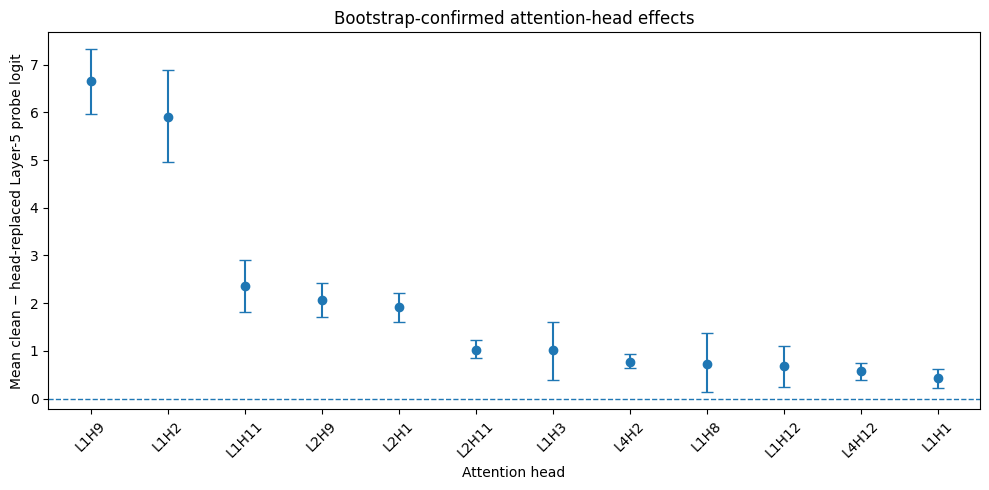


Saved bootstrap results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


In [ ]:
N_BOOTSTRAPS = 5000
bootstrap_rng = np.random.default_rng(SEED)

head_bootstrap_rows = []

for (layer, head), head_df in head_scan_per_sequence.groupby(
    ["layer", "head"]
):
    effects = head_df["logit_drop"].to_numpy()

    bootstrap_means = np.empty(N_BOOTSTRAPS)

    for bootstrap_index in range(N_BOOTSTRAPS):
        sampled = bootstrap_rng.choice(
            effects,
            size=len(effects),
            replace=True,
        )

        bootstrap_means[bootstrap_index] = sampled.mean()

    head_bootstrap_rows.append({
        "layer": layer,
        "head": head,
        "component": f"L{layer}H{head}",
        "mean_logit_drop": effects.mean(),
        "median_logit_drop": np.median(effects),
        "ci_2.5": np.percentile(
            bootstrap_means,
            2.5,
        ),
        "ci_97.5": np.percentile(
            bootstrap_means,
            97.5,
        ),
        "standard_error": bootstrap_means.std(ddof=1),
        "fraction_positive": np.mean(effects > 0),
    })


head_bootstrap_summary = (
    pd.DataFrame(head_bootstrap_rows)
    .sort_values(
        "mean_logit_drop",
        ascending=False,
    )
    .reset_index(drop=True)
)

# A conservative candidate requires:
# 1. positive mean effect,
# 2. 95% bootstrap interval above zero,
# 3. effect positive in at least 60% of promoters.
head_bootstrap_summary["robust_candidate"] = (
    (head_bootstrap_summary["ci_2.5"] > 0)
    & (head_bootstrap_summary["fraction_positive"] >= 0.60)
)

display(head_bootstrap_summary)

robust_heads = head_bootstrap_summary[
    head_bootstrap_summary["robust_candidate"]
].copy()

print("\nRobust candidate heads:")
display(robust_heads)

# Plot the top 12 heads with confidence intervals.
top_head_plot = head_bootstrap_summary.head(12).copy()

means = top_head_plot["mean_logit_drop"].to_numpy()

lower_errors = (
    means
    - top_head_plot["ci_2.5"].to_numpy()
)

upper_errors = (
    top_head_plot["ci_97.5"].to_numpy()
    - means
)

plt.figure(figsize=(10, 5))

plt.errorbar(
    top_head_plot["component"],
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=4,
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Attention head")
plt.ylabel("Mean clean − head-replaced Layer-5 probe logit")
plt.title(
    "Bootstrap-confirmed attention-head effects"
)

plt.xticks(rotation=45)
plt.tight_layout()

head_bootstrap_figure_path = (
    COMPONENT_DIR
    / "attention_head_bootstrap_confidence_intervals.png"
)

plt.savefig(
    head_bootstrap_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

head_bootstrap_summary.to_csv(
    COMPONENT_DIR
    / "attention_head_bootstrap_summary.csv",
    index=False,
)

print("\nSaved bootstrap results to:", COMPONENT_DIR)

# Cell 19 — joint-head intervention test— Test whether top heads act additively or redundantly

In [ ]:
TOP_HEAD_SETS = {
    "L1H9": [(0, 8)],
    "L1H2": [(0, 1)],
    "L1H9+L1H2": [(0, 8), (0, 1)],
    "L1H9+L1H2+L1H11": [(0, 8), (0, 1), (0, 10)],
    "L1H9+L1H2+L2H9": [(0, 8), (0, 1), (1, 8)],
}


def make_multi_head_replacement_hook(
    replacements,
):
    """
    replacements:
        dictionary mapping head_index -> mean_vector
        for one attention layer.
    """
    def hook(module, inputs, output):
        if not torch.is_tensor(output):
            raise TypeError(
                f"Expected tensor output, received {type(output)}"
            )

        reshaped = output.reshape(
            output.shape[0],
            NUM_HEADS,
            HEAD_DIM,
        ).clone()

        for head_index, mean_vector in replacements.items():
            replacement = mean_vector.to(
                device=output.device,
                dtype=output.dtype,
            )

            reshaped[:, head_index, :] = replacement

        return reshaped.reshape(
            output.shape[0],
            backbone.config.hidden_size,
        )

    return hook


def extract_layer5_with_multiple_head_replacements(
    sequences,
    head_specs,
    batch_size=32,
):
    """
    head_specs:
        list of (layer_index, head_index) tuples
    """
    replacements_by_layer = {}

    for layer_index, head_index in head_specs:
        replacements_by_layer.setdefault(
            layer_index,
            {},
        )[head_index] = (
            head_reference_means[layer_index][head_index]
        )

    handles = []

    for layer_index, replacements in replacements_by_layer.items():
        module = (
            backbone.encoder.layer[layer_index]
            .attention.self
        )

        handles.append(
            module.register_forward_hook(
                make_multi_head_replacement_hook(
                    replacements
                )
            )
        )

    try:
        dataloader = DataLoader(
            list(sequences),
            batch_size=batch_size,
            shuffle=False,
        )

        representation_batches = []

        for sequence_batch in tqdm(
            dataloader,
            desc="Joint head intervention",
        ):
            encoded = tokenizer(
                list(sequence_batch),
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=128,
            )

            encoded = {
                key: value.to(device)
                for key, value in encoded.items()
            }

            token_counts = (
                encoded["attention_mask"]
                .sum(dim=1)
                .tolist()
            )

            captured_layers.clear()

            with torch.no_grad():
                _ = backbone(
                    **encoded,
                    return_dict=False,
                )

            pooled_layer5 = split_and_content_mean_pool(
                captured_layers[LAYER5_INDEX],
                token_counts,
            )

            representation_batches.append(
                pooled_layer5.cpu()
            )

        representations = (
            torch.cat(representation_batches, dim=0)
            .numpy()
        )

        logits = layer5_probe.decision_function(
            representations
        )

        probabilities = layer5_probe.predict_proba(
            representations
        )[:, 1]

        return representations, logits, probabilities

    finally:
        for handle in handles:
            handle.remove()


joint_head_rows = []
joint_head_per_sequence_rows = []

for condition_name, head_specs in TOP_HEAD_SETS.items():
    print(f"\nRunning {condition_name}...")

    (
        joint_representations,
        joint_logits,
        joint_probabilities,
    ) = extract_layer5_with_multiple_head_replacements(
        recognized_sequences,
        head_specs=head_specs,
        batch_size=32,
    )

    logit_drops = (
        clean_head_scan_logits
        - joint_logits
    )

    probability_drops = (
        clean_head_scan_probabilities
        - joint_probabilities
    )

    joint_head_rows.append({
        "condition": condition_name,
        "number_of_heads": len(head_specs),
        "mean_replaced_logit": joint_logits.mean(),
        "mean_logit_drop": logit_drops.mean(),
        "median_logit_drop": np.median(logit_drops),
        "std_logit_drop": logit_drops.std(ddof=1),
        "fraction_positive_drop": np.mean(logit_drops > 0),
        "mean_probability_drop": probability_drops.mean(),
        "fraction_remaining_positive": np.mean(
            joint_logits > 0
        ),
    })

    for sequence_index in range(len(recognized_sequences)):
        joint_head_per_sequence_rows.append({
            "sequence_index": sequence_index,
            "condition": condition_name,
            "clean_logit": clean_head_scan_logits[
                sequence_index
            ],
            "replaced_logit": joint_logits[
                sequence_index
            ],
            "logit_drop": logit_drops[
                sequence_index
            ],
        })


joint_head_summary = pd.DataFrame(joint_head_rows)
joint_head_per_sequence = pd.DataFrame(
    joint_head_per_sequence_rows
)

display(
    joint_head_summary.sort_values(
        "mean_logit_drop",
        ascending=False,
    )
)

# Compare the observed two-head effect with the sum of
# the individual effects.
individual_l1h9_drop = head_scan_summary.loc[
    (head_scan_summary["layer"] == 1)
    & (head_scan_summary["head"] == 9),
    "mean_logit_drop",
].iloc[0]

individual_l1h2_drop = head_scan_summary.loc[
    (head_scan_summary["layer"] == 1)
    & (head_scan_summary["head"] == 2),
    "mean_logit_drop",
].iloc[0]

observed_pair_drop = joint_head_summary.loc[
    joint_head_summary["condition"] == "L1H9+L1H2",
    "mean_logit_drop",
].iloc[0]

expected_additive_drop = (
    individual_l1h9_drop
    + individual_l1h2_drop
)

interaction_term = (
    observed_pair_drop
    - expected_additive_drop
)

print("\nL1H9 individual drop:", individual_l1h9_drop)
print("L1H2 individual drop:", individual_l1h2_drop)
print("Expected additive drop:", expected_additive_drop)
print("Observed pair drop:", observed_pair_drop)
print("Interaction term:", interaction_term)

joint_head_summary.to_csv(
    COMPONENT_DIR / "joint_head_intervention_summary.csv",
    index=False,
)

joint_head_per_sequence.to_csv(
    COMPONENT_DIR / "joint_head_intervention_per_sequence.csv",
    index=False,
)

print("\nJoint-head results saved to:", COMPONENT_DIR)


Running L1H9...


Joint head intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Running L1H2...


Joint head intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Running L1H9+L1H2...


...

Joint head intervention:   0%|          | 0/10 [00:00<?, ?it/s]


Running L1H9+L1H2+L2H9...


Joint head intervention:   0%|          | 0/10 [00:00<?, ?it/s]

,condition,number_of_heads,mean_replaced_logit,mean_logit_drop,median_logit_drop,std_logit_drop,fraction_positive_drop,mean_probability_drop,fraction_remaining_positive
4,L1H9+L1H2+L2H9,3,-2.707200,9.195443,7.993988,8.637093,0.924399,0.582233,0.353952
2,L1H9+L1H2,2,-1.630164,8.118408,7.216421,7.963465,0.910653,0.540817,0.388316
3,L1H9+L1H2+L1H11,3,-0.687927,7.176170,7.778137,7.873120,0.872852,0.514929,0.408935
0,L1H9,1,-0.157686,6.645930,6.717012,5.949915,0.879725,0.461069,0.484536
1,L1H2,1,0.589018,5.899225,4.635349,8.305516,0.797251,0.399269,0.539519



L1H9 individual drop: 6.64592952611146
L1H2 individual drop: 5.89922504508884
Expected additive drop: 12.5451545712003
Observed pair drop: 8.118407624322709
Interaction term: -4.426746946877591

Joint-head results saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization


# Cell 20 — Bootstrap redundancy and interaction among top heads

In [ ]:
N_BOOTSTRAPS = 5000
rng = np.random.default_rng(SEED)

# Individual per-sequence drops
l1h9_effects = (
    head_scan_per_sequence[
        (head_scan_per_sequence["layer"] == 1)
        & (head_scan_per_sequence["head"] == 9)
    ]
    .sort_values("sequence_index")["logit_drop"]
    .to_numpy()
)

l1h2_effects = (
    head_scan_per_sequence[
        (head_scan_per_sequence["layer"] == 1)
        & (head_scan_per_sequence["head"] == 2)
    ]
    .sort_values("sequence_index")["logit_drop"]
    .to_numpy()
)

l2h9_effects = (
    head_scan_per_sequence[
        (head_scan_per_sequence["layer"] == 2)
        & (head_scan_per_sequence["head"] == 9)
    ]
    .sort_values("sequence_index")["logit_drop"]
    .to_numpy()
)

# Joint per-sequence drops
pair_effects = (
    joint_head_per_sequence[
        joint_head_per_sequence["condition"] == "L1H9+L1H2"
    ]
    .sort_values("sequence_index")["logit_drop"]
    .to_numpy()
)

triple_l2h9_effects = (
    joint_head_per_sequence[
        joint_head_per_sequence["condition"]
        == "L1H9+L1H2+L2H9"
    ]
    .sort_values("sequence_index")["logit_drop"]
    .to_numpy()
)

# Per-sequence interaction terms
pair_interaction = (
    pair_effects
    - l1h9_effects
    - l1h2_effects
)

l2h9_increment = (
    triple_l2h9_effects
    - pair_effects
)

expected_l2h9_increment = l2h9_effects

l2h9_interaction = (
    l2h9_increment
    - expected_l2h9_increment
)

bootstrap_rows = []

for name, effects in {
    "L1H9_L1H2_interaction": pair_interaction,
    "L2H9_increment_after_pair": l2h9_increment,
    "L2H9_context_interaction": l2h9_interaction,
}.items():

    bootstrap_means = np.empty(N_BOOTSTRAPS)

    for bootstrap_index in range(N_BOOTSTRAPS):
        sampled = rng.choice(
            effects,
            size=len(effects),
            replace=True,
        )

        bootstrap_means[bootstrap_index] = sampled.mean()

    bootstrap_rows.append({
        "effect": name,
        "mean": effects.mean(),
        "median": np.median(effects),
        "ci_2.5": np.percentile(
            bootstrap_means,
            2.5,
        ),
        "ci_97.5": np.percentile(
            bootstrap_means,
            97.5,
        ),
        "fraction_positive": np.mean(effects > 0),
    })


interaction_summary = pd.DataFrame(
    bootstrap_rows
)

display(interaction_summary)

print(
    "\nPair interpretation:",
    "redundant/saturating"
    if interaction_summary.loc[
        interaction_summary["effect"]
        == "L1H9_L1H2_interaction",
        "ci_97.5",
    ].iloc[0] < 0
    else "uncertain",
)

interaction_summary.to_csv(
    COMPONENT_DIR
    / "top_head_interaction_bootstrap_summary.csv",
    index=False,
)

print(
    "\nInteraction summary saved to:",
    COMPONENT_DIR
    / "top_head_interaction_bootstrap_summary.csv",
)

,effect,mean,median,ci_2.5,ci_97.5,fraction_positive
0,L1H9_L1H2_interaction,-4.426747,-3.818282,-5.453394,-3.332353,0.274914
1,L2H9_increment_after_pair,1.077036,0.797537,0.693157,1.450773,0.615120
2,L2H9_context_interaction,-0.994959,-1.179757,-1.469096,-0.523696,0.367698



Pair interpretation: redundant/saturating

Interaction summary saved to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization/top_head_interaction_bootstrap_summary.csv


In [ ]:
# Cell 21 — Final component-localization summary and conclusions

# Select the strongest branch and head candidates.
top_branch_candidates = (
    mean_replacement_summary
    .sort_values(
        ["mean_logit_drop", "fraction_positive_drop"],
        ascending=False,
    )
    .head(6)
    .copy()
)

top_head_candidates = (
    head_bootstrap_summary
    .sort_values(
        ["mean_logit_drop", "fraction_positive"],
        ascending=False,
    )
    .head(10)
    .copy()
)

component_summary = pd.DataFrame([
    {
        "analysis": "Best linear-readout layer",
        "component": "Layer 5 residual stream",
        "effect": (
            layerwise_probe_results.loc[
                layerwise_probe_results["layer"] == 5,
                "test_roc_auc",
            ].iloc[0]
        ),
        "metric": "test ROC-AUC",
        "interpretation": (
            "Promoter information is most linearly accessible "
            "at Layer 5."
        ),
    },
    {
        "analysis": "Strongest mean-replaced branch",
        "component": "Layer 1 attention",
        "effect": (
            mean_replacement_summary.loc[
                (mean_replacement_summary["layer"] == 1)
                & (
                    mean_replacement_summary["branch"]
                    == "attention"
                ),
                "mean_logit_drop",
            ].iloc[0]
        ),
        "metric": "mean Layer-5 probe-logit drop",
        "interpretation": (
            "Early attention carries sequence-specific "
            "information needed for the Layer-5 readout."
        ),
    },
    {
        "analysis": "Strongest MLP branch",
        "component": "Layer 1 MLP",
        "effect": (
            mean_replacement_summary.loc[
                (mean_replacement_summary["layer"] == 1)
                & (
                    mean_replacement_summary["branch"]
                    == "mlp"
                ),
                "mean_logit_drop",
            ].iloc[0]
        ),
        "metric": "mean Layer-5 probe-logit drop",
        "interpretation": (
            "Layer 1 MLP is also strongly required for the "
            "promoter-associated representation."
        ),
    },
    {
        "analysis": "Strongest attention head",
        "component": "L1H9",
        "effect": (
            head_bootstrap_summary.loc[
                head_bootstrap_summary["component"] == "L1H9",
                "mean_logit_drop",
            ].iloc[0]
        ),
        "metric": "mean Layer-5 probe-logit drop",
        "interpretation": (
            "Dominant early attention-head candidate."
        ),
    },
    {
        "analysis": "Second strongest attention head",
        "component": "L1H2",
        "effect": (
            head_bootstrap_summary.loc[
                head_bootstrap_summary["component"] == "L1H2",
                "mean_logit_drop",
            ].iloc[0]
        ),
        "metric": "mean Layer-5 probe-logit drop",
        "interpretation": (
            "Second dominant Layer-1 attention-head candidate."
        ),
    },
    {
        "analysis": "Top-head interaction",
        "component": "L1H9 + L1H2",
        "effect": (
            interaction_summary.loc[
                interaction_summary["effect"]
                == "L1H9_L1H2_interaction",
                "mean",
            ].iloc[0]
        ),
        "metric": "interaction term",
        "interpretation": (
            "Negative interaction supports redundancy "
            "or saturation rather than additivity."
        ),
    },
    {
        "analysis": "Cross-layer incremental contribution",
        "component": "L2H9 after L1H9 + L1H2",
        "effect": (
            interaction_summary.loc[
                interaction_summary["effect"]
                == "L2H9_increment_after_pair",
                "mean",
            ].iloc[0]
        ),
        "metric": "incremental mean logit drop",
        "interpretation": (
            "L2H9 contributes additional partly independent "
            "promoter-relevant information."
        ),
    },
])

print("Final component summary:")
display(component_summary)

print("\nTop branch candidates:")
display(top_branch_candidates)

print("\nTop attention-head candidates:")
display(top_head_candidates)

# Save final tables.
component_summary.to_csv(
    COMPONENT_DIR / "component_localization_summary.csv",
    index=False,
)

top_branch_candidates.to_csv(
    COMPONENT_DIR / "top_branch_candidates.csv",
    index=False,
)

top_head_candidates.to_csv(
    COMPONENT_DIR / "top_attention_head_candidates.csv",
    index=False,
)

final_conclusions = f"""
# Notebook 3: Promoter Component Localization

## Experimental target

A fixed linear diagnostic probe applied to mean-pooled Layer-5
representations from baseline, non-fine-tuned DNABERT-2.

The principal cohort contained 291 true promoter sequences that had
positive clean Layer-5 probe logits. The remaining 109 true promoters
were retained as a separate clean probe-failure cohort.

## Layerwise localization

Promoter information was linearly accessible throughout the network,
but Layer 5 produced the strongest test performance:

- Layer-5 balanced accuracy: 0.735
- Layer-5 ROC-AUC: 0.811

Layer 8 was the strongest secondary peak. Performance declined somewhat
in the final layers.

Layer 5 also showed the largest probe-logit loss under
dinucleotide-preserving corruption, making it the strongest joint
candidate for linear accessibility and higher-order sequence sensitivity.

## Branch-level localization

Zero ablation caused severe distribution shifts and produced several
sign reversals. Therefore, branch ranking was based primarily on
reference-mean replacement.

The strongest mean-replacement effects were:

- Layer 1 attention: 7.731 mean-logit drop
- Layer 1 MLP: 7.561
- Layer 2 attention: 5.183
- Layer 4 attention: 3.364

These effects indicate that early Layer-1 computation is especially
important for constructing the promoter-associated Layer-5 representation.

## Attention-head localization

The strongest individual heads were:

- L1H9: mean drop 6.646,
  bootstrap 95% CI [5.970, 7.316],
  positive for 88.0% of promoters

- L1H2: mean drop 5.899,
  bootstrap 95% CI [4.961, 6.892],
  positive for 79.7% of promoters

Secondary candidates included:

- L1H11
- L2H9
- L2H1
- L2H11

No single Layer-4 head reproduced the full Layer-4 attention-branch
effect, suggesting a more distributed or interaction-dependent
contribution at that layer.

## Head interactions

Joint replacement of L1H9 and L1H2 produced a mean-logit drop of 8.118,
compared with an additive expectation of 12.545.

The interaction term was:

- mean: -4.427
- bootstrap 95% CI: [-5.453, -3.332]

This supports strong redundancy or saturation between L1H9 and L1H2.

Adding L2H9 to the Layer-1 pair produced an additional mean drop of 1.077,
with bootstrap 95% CI [0.693, 1.451]. Thus, L2H9 contributes additional
but partly overlapping information.

## Supported working model

The promoter-associated representation is not created by a single late
component. It is built early in the network, with Layer-1 attention and
MLP computation playing dominant roles.

Within attention, L1H9 and L1H2 form the strongest sparse candidate set.
They carry overlapping promoter-relevant information. L2H9 provides an
additional cross-layer contribution. Layer 4 appears more distributed
across heads.

## Interpretation boundary

These experiments establish component sensitivity of a trained
diagnostic readout. They do not yet show:

- what nucleotide motifs or biological variables the heads encode,
- that the components form a complete faithful circuit,
- that the same components control a native promoter classifier,
- or that mean replacement is perfectly on-distribution.

Attribution and ablation rank candidate components. Activation patching,
clean-to-corrupt rescue, and biological stimulus tests are required for
strong causal and mechanistic claims.

## Next stage

Use clean and corrupted sequence pairs to perform activation patching:

1. run the corrupted sequence,
2. inject clean activations from candidate components,
3. measure restoration of the Layer-5 promoter-probe logit,
4. test L1H9, L1H2, L2H9, Layer-1 MLP, and combinations,
5. compare necessity with rescue and delivery.

This will be Notebook 4: Promoter Causal Interventions.
"""

conclusion_path = (
    COMPONENT_DIR / "NOTEBOOK_3_CONCLUSIONS.md"
)

with open(conclusion_path, "w") as file:
    file.write(final_conclusions.strip())

print("\nSaved component summary to:")
print(COMPONENT_DIR / "component_localization_summary.csv")

print("\nSaved conclusions to:")
print(conclusion_path)

print("\nNotebook 3 complete.")

Final component summary:


,analysis,component,effect,metric,interpretation
0,Best linear-readout layer,Layer 5 residual stream,0.810638,test ROC-AUC,Promoter information is most linearly accessib...
1,Strongest mean-replaced branch,Layer 1 attention,7.730643,mean Layer-5 probe-logit drop,Early attention carries sequence-specific info...
2,Strongest MLP branch,Layer 1 MLP,7.561372,mean Layer-5 probe-logit drop,Layer 1 MLP is also strongly required for the ...
3,Strongest attention head,L1H9,6.645930,mean Layer-5 probe-logit drop,Dominant early attention-head candidate.
4,Second strongest attention head,L1H2,5.899225,mean Layer-5 probe-logit drop,Second dominant Layer-1 attention-head candidate.
5,Top-head interaction,L1H9 + L1H2,-4.426747,interaction term,Negative interaction supports redundancy or sa...
6,Cross-layer incremental contribution,L2H9 after L1H9 + L1H2,1.077036,incremental mean logit drop,L2H9 contributes additional partly independent...



Top branch candidates:


,layer,branch,mean_clean_logit,mean_replaced_logit,mean_logit_drop,median_logit_drop,std_logit_drop,fraction_positive_drop,mean_probability_drop,fraction_remaining_positive
0,1,attention,6.488243,-1.242400,7.730643,7.319912,6.638149,0.910653,0.552976,0.374570
1,1,mlp,6.488243,-1.073129,7.561372,6.905104,7.543862,0.886598,0.534359,0.371134
2,2,attention,6.488243,1.305461,5.182783,5.259867,5.252126,0.831615,0.387570,0.549828
6,4,attention,6.488243,3.124483,3.363761,3.037795,4.532827,0.800687,0.171525,0.780069
7,4,mlp,6.488243,4.136741,2.351502,1.295547,5.218363,0.621993,-0.045883,1.000000
8,5,attention,6.488243,4.193112,2.295132,1.333619,6.555587,0.594502,0.154725,0.783505



Top attention-head candidates:


,layer,head,component,mean_logit_drop,median_logit_drop,ci_2.5,ci_97.5,standard_error,fraction_positive,robust_candidate
0,1,9,L1H9,6.645930,6.717012,5.970332,7.316443,0.344539,0.879725,True
1,1,2,L1H2,5.899225,4.635349,4.961343,6.891519,0.491658,0.797251,True
2,1,11,L1H11,2.351846,2.863939,1.809797,2.909898,0.278390,0.704467,True
3,2,9,L2H9,2.071995,1.916218,1.721578,2.429242,0.181414,0.780069,True
4,2,1,L2H1,1.918078,1.878127,1.610254,2.221920,0.157354,0.786942,True
5,2,11,L2H11,1.030021,0.848433,0.846423,1.220912,0.095733,0.749141,True
6,1,3,L1H3,1.022529,0.820142,0.397836,1.616333,0.307832,0.694158,True
7,4,2,L4H2,0.775925,0.645268,0.632407,0.925950,0.074807,0.749141,True
8,1,8,L1H8,0.720395,-0.130547,0.139002,1.375635,0.314250,0.470790,False
9,1,12,L1H12,0.678015,0.415507,0.237061,1.096083,0.218148,0.628866,True



Saved component summary to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization/component_localization_summary.csv

Saved conclusions to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_component_localization/NOTEBOOK_3_CONCLUSIONS.md

Notebook 3 complete.
